# Energy-Tweedie diffusion: MNIST presentation

This notebook reproduces the five MNIST sampling paths, endpoint grids, matched-RMS progress, nearest training images, and quantitative table. Download the paper checkpoint `final.pt` from the [MNIST model release](https://github.com/andleb/et/releases/tag/MNIST_model) and place it at `models/mnist/posterior/final.pt`. The included `exp/train_mnist.sh` trains the model from its saved configuration. Run `exp/sample_diffusion_mnist.sh` with the checkpoint in place, then run this notebook. Results and figures are saved under `res/mnist/model_selection/`.


# Setup

## Imports and project root

In [ ]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from omegaconf import OmegaConf
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "exp/reproduce_diffusion_mnist.ipynb").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
ENGRESSION_PATH = ROOT / "src" / "engression"
if str(ENGRESSION_PATH) not in sys.path:
    sys.path.insert(1, str(ENGRESSION_PATH))

ROOT


In [2]:
import onnx
import onnxruntime

print("ONNX:", onnx.__version__)
print("ONNX Runtime:", onnxruntime.__version__)


ONNX: 1.18.0
ONNX Runtime: 1.22.1


In [3]:
from utils.experiment_io import save_torch_atomic, write_csv_atomic, write_json_atomic
from utils.mnist import (
    MNIST_DIM,
    MNISTUint8Dataset,
    build_mnist_sampling_schedule,
    make_mnist_image_grid,
    make_mnist_loader,
)
from utils.mnist_eval import (
    ONNX_MNIST12_FEATURE_OUTPUT_NAME,
    ONNX_MNIST12_URL,
    ONNXMNIST12Classifier,
    ONNXMNIST12FeatureClassifier,
    ensure_onnx_mnist12_checkpoint,
    ensure_onnx_mnist12_feature_checkpoint,
    mnist_prediction_metrics,
    mnist_representation_energy_distance,
    mnist_stratified_bootstrap_primary_metrics,
    nearest_reference_pixel_rmse,
)


In [ ]:
torch.set_float32_matmul_precision("high")

MNIST_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT:", ROOT)
print("DEVICE:", MNIST_DEVICE)
if MNIST_DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(MNIST_DEVICE))
    print(
        "GPU memory GB:",
        round(torch.cuda.get_device_properties(MNIST_DEVICE).total_memory / 1024**3, 2),
    )


# Configuration

Each sampling path has a configuration in `exp/configs/` specifying the model, sampler, seeds, and RMS endpoints.


In [6]:
MNIST_CONFIGURED_PATH_FILES = {
    "gaussian": ROOT / "exp/configs/diffusion-mnist-gaussian-isotropic.yaml",
    "gaussian_non_diagonal": ROOT
    / "exp/configs/diffusion-mnist-gaussian-non-diagonal.yaml",
    "generalized_isotropic": ROOT
    / "exp/configs/diffusion-mnist-generalized-isotropic.yaml",
    "fixed_non_diagonal": ROOT
    / "exp/configs/diffusion-mnist-generalized-non-diagonal.yaml",
    "joint": ROOT / "exp/configs/diffusion-mnist-joint.yaml",
}
MNIST_CONFIGURED_PATH_CONFIGS = {
    path_name: OmegaConf.load(config_path)
    for path_name, config_path in MNIST_CONFIGURED_PATH_FILES.items()
}
for path_config in MNIST_CONFIGURED_PATH_CONFIGS.values():
    OmegaConf.resolve(path_config)

MNIST_PATH_LABELS = {
    "gaussian": "Gaussian / isotropic",
    "gaussian_non_diagonal": "Gaussian / non-diagonal",
    "generalized_isotropic": "Generalized / isotropic",
    "fixed_non_diagonal": "Generalized / non-diagonal",
    "joint": "Joint five-parameter path",
}
MNIST_PATH_COLORS = {
    "gaussian": "#5f6368",
    "gaussian_non_diagonal": "#7b6fd0",
    "generalized_isotropic": "#2a9d8f",
    "fixed_non_diagonal": "#2f6fb0",
    "joint": "#c25a37",
}
MNIST_CONFIG = next(iter(MNIST_CONFIGURED_PATH_CONFIGS.values()))
MNIST_MODEL_ROOT = ROOT / str(MNIST_CONFIG.model_root)
MNIST_PRODUCTION_RUN_NAME = str(MNIST_CONFIG.model.run_name)
MNIST_PRODUCTION_LABEL = str(MNIST_CONFIG.model.label)
MNIST_OUT_DIR = ROOT / str(MNIST_CONFIG.output_root)
MNIST_FIG_DIR = MNIST_OUT_DIR / "figs"
MNIST_FIG_DIR.mkdir(parents=True, exist_ok=True)
PRODUCTION_CHUNKS = int(MNIST_CONFIG.production.chunks_per_seed)
PRODUCTION_CHUNK_SAMPLES = int(MNIST_CONFIG.production.chunk_samples)
MNIST_GENERATION_SEEDS = list(MNIST_CONFIG.production.seeds)
MNIST_FIGURE_SEED = MNIST_GENERATION_SEEDS[0]
RMS_START = float(MNIST_CONFIG.schedule.actual_rms_start)
RMS_END = float(MNIST_CONFIG.schedule.actual_rms_end)
MNIST_PRODUCTION_SAMPLER_CONFIG = {
    **OmegaConf.to_container(MNIST_CONFIG.sampler, resolve=True),
    "n_samples": PRODUCTION_CHUNK_SAMPLES,
}

MNIST_PLOT_RC = {
    "figure.dpi": 200,
    "savefig.dpi": 300,
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
}

presentation_config = {
    "production_run_name": MNIST_PRODUCTION_RUN_NAME,
    "production_label": MNIST_PRODUCTION_LABEL,
    "paths": list(MNIST_PATH_LABELS),
    "configured_path_files": {
        path_name: str(config_path.relative_to(ROOT))
        for path_name, config_path in MNIST_CONFIGURED_PATH_FILES.items()
    },
    "generation_seeds": MNIST_GENERATION_SEEDS,
    "chunks_per_seed": PRODUCTION_CHUNKS,
    "chunk_samples": PRODUCTION_CHUNK_SAMPLES,
    "sampler": dict(MNIST_PRODUCTION_SAMPLER_CONFIG),
    "actual_rms_start": RMS_START,
    "actual_rms_end": RMS_END,
}
presentation_config


{'analysis_version': 'mnist_common_rms_model_selection_v1',
 'production_run_name': 'posterior',
 'production_label': 'h2560 / rho4 full',
 'paths': ['gaussian',
  'gaussian_non_diagonal',
  'generalized_isotropic',
  'fixed_non_diagonal',
  'joint'],
 'configured_path_files': {'gaussian_non_diagonal': 'exp/configs/mnist-prod-gaussian-non-diagonal.yaml',
  'generalized_isotropic': 'exp/configs/mnist-prod-generalized-isotropic.yaml'},
 'generation_seeds': [2718, 3141, 5772],
 'chunks_per_seed': 2,
 'chunk_samples': 128,
 'sampler': {'n_samples': 128,
  'n_levels': 64,
  'first_level_steps': 1000,
  'n_steps_each': 100,
  'n_mc': 256,
  'base_lr': 0.0015625,
  'alpha_cap': 0.025,
  'update_clip': 10.0,
  'state_clip': None},
 'actual_rms_start': 2.62858779876867,
 'actual_rms_end': 0.19714408490765023}

**Sample bundle paths**


Each bundle contains one chunk of samples for a path and generation seed.


In [7]:
def mnist_production_bundle_path(path_name, generation_seed, chunk_index):
    return (
        MNIST_OUT_DIR
        / path_name
        / "runs"
        / (
            f"{MNIST_PRODUCTION_RUN_NAME}__{path_name}__"
            f"s{int(generation_seed)}_chunk{int(chunk_index)}.pt"
        )
    )


# Checkpoint and parameter paths

Load the training configuration to construct the five sampling paths.


In [8]:
mnist_production_model_dir = MNIST_MODEL_ROOT / MNIST_PRODUCTION_RUN_NAME
mnist_production_config = OmegaConf.load(mnist_production_model_dir / "config.yaml")
mnist_production_checkpoint = mnist_production_model_dir / str(
    MNIST_CONFIG.model.checkpoint
)
mnist_model_status_df = pd.DataFrame(
    [
        {
            "run_name": MNIST_PRODUCTION_RUN_NAME,
            "label": MNIST_PRODUCTION_LABEL,
            "checkpoint": mnist_production_checkpoint.name,
            "hidden_dim": int(mnist_production_config.model.hidden_dim),
            "rho_min": float(mnist_production_config.noise.rho_min),
            "rho_max": float(mnist_production_config.noise.rho_max),
            "beta_min": float(mnist_production_config.noise.beta_min),
            "beta_max": float(mnist_production_config.noise.beta_max),
            "lambda_min": float(mnist_production_config.noise.lambda_min),
            "lambda_max": float(mnist_production_config.noise.lambda_max),
            "spd_radius_max": float(mnist_production_config.noise.spd.radius_max),
        }
    ]
)
write_csv_atomic(mnist_model_status_df, MNIST_OUT_DIR / "model_status.csv")
mnist_model_status_df


,run_name,label,checkpoint,checkpoint_size_gb,hidden_dim,rho_min,rho_max,beta_min,beta_max,lambda_min,lambda_max,spd_radius_max
0,posterior,h2560 / rho4 full,final.pt,0.428071,2560,0.025,6.0,1.3,2.0,1.0,2.5,0.7


All five paths share one actual per-pixel RMS schedule

$$
r(s)=r_0\left(\frac{r_1}{r_0}\right)^s,
\qquad (r_0,r_1)=(2.629,0.197),
\qquad s\in[0,1],
$$

and one sampler budget, so the comparisons isolate the noise law and covariance geometry. For each path the reference scale is $\rho(s)=r(s)\lambda(s)^{1/\beta(s)}$. The four fixed arms form the complete product of two radial laws and two geometries:

- **Gaussian radial law:** $(\beta,\lambda)=(2,1)$, for which the Energy-Tweedie score reduces to the ordinary posterior-mean Tweedie score.
- **Generalized radial law:** $(\beta,\lambda)=(1.4,1.8)$.
- **Isotropic geometry:** $(u,v)=(0,0)$.
- **Non-diagonal geometry:** $(u,v)=(0,0.6)$.

The fifth path jointly changes the radial law and geometry,

$$
\beta(s)=2-0.6s,
\quad
\lambda(s)=1+0.8s,
\quad
u(s)=0.3\sin(\pi s),
\quad
v(s)=0.6s,
$$

from the Gaussian/isotropic start to the generalized/non-diagonal endpoint. Here $S(u,v)=\begin{pmatrix}1+u&v\\v&1-u\end{pmatrix}$ is the $2\times2$ covariance block repeated over horizontally adjacent pixel pairs.

In [9]:
mnist_schedules = {}
mnist_schedule_rows = []
for path_name in MNIST_PATH_LABELS:
    schedule = build_mnist_sampling_schedule(
        mnist_production_config, MNIST_CONFIGURED_PATH_CONFIGS[path_name], "cpu"
    )
    mnist_schedules[path_name] = schedule
    for level in range(len(schedule["progress"])):
        mnist_schedule_rows.append(
            {
                "path": path_name,
                "level": level,
                "progress": float(schedule["progress"][level]),
                "beta": float(schedule["beta"][level]),
                "lambda": float(schedule["lam"][level]),
                "rho": float(schedule["rho"][level]),
                "sigma": float(schedule["sigma"][level]),
                "actual_rms": float(schedule["actual_rms"][level]),
                "u": float(schedule["u"][level]),
                "v": float(schedule["v"][level]),
            }
        )

mnist_schedule_df = pd.DataFrame(mnist_schedule_rows)
write_csv_atomic(mnist_schedule_df, MNIST_OUT_DIR / "schedules.csv")
save_torch_atomic(
    {
        path_name: {
            key: torch.as_tensor(values).detach().cpu()
            for key, values in schedule.items()
        }
        for path_name, schedule in mnist_schedules.items()
    },
    MNIST_OUT_DIR / "schedules.pt",
)
mnist_schedule_df.groupby("path").agg(
    n_levels=("level", "size"),
    rho_start=("rho", "first"),
    rho_end=("rho", "last"),
    rms_start=("actual_rms", "first"),
    rms_end=("actual_rms", "last"),
    beta_min=("beta", "min"),
    beta_max=("beta", "max"),
    lambda_min=("lambda", "min"),
    lambda_max=("lambda", "max"),
)


,n_levels,rho_start,rho_end,rms_start,rms_end,beta_min,beta_max,lambda_min,lambda_max
path,,,,,,,,,
fixed_non_diagonal,64,4.000000,0.300000,2.628587,0.197144,1.4,1.4,1.8,1.8
gaussian,64,2.628588,0.197144,2.628588,0.197144,2.0,2.0,1.0,1.0
gaussian_non_diagonal,64,2.628588,0.197144,2.628588,0.197144,2.0,2.0,1.0,1.0
generalized_isotropic,64,4.000000,0.300000,2.628587,0.197144,1.4,1.4,1.8,1.8
joint,64,2.628588,0.300000,2.628588,0.197144,1.4,2.0,1.0,1.8


## Path geometry

The figure shows exactly what changes along each schedule. The actual per-pixel RMS includes the effects of $\beta$ and $\lambda$ and is the quantity used to order the sampler levels. The $(u,v)$ panel shows the structured covariance path inside the training disk.

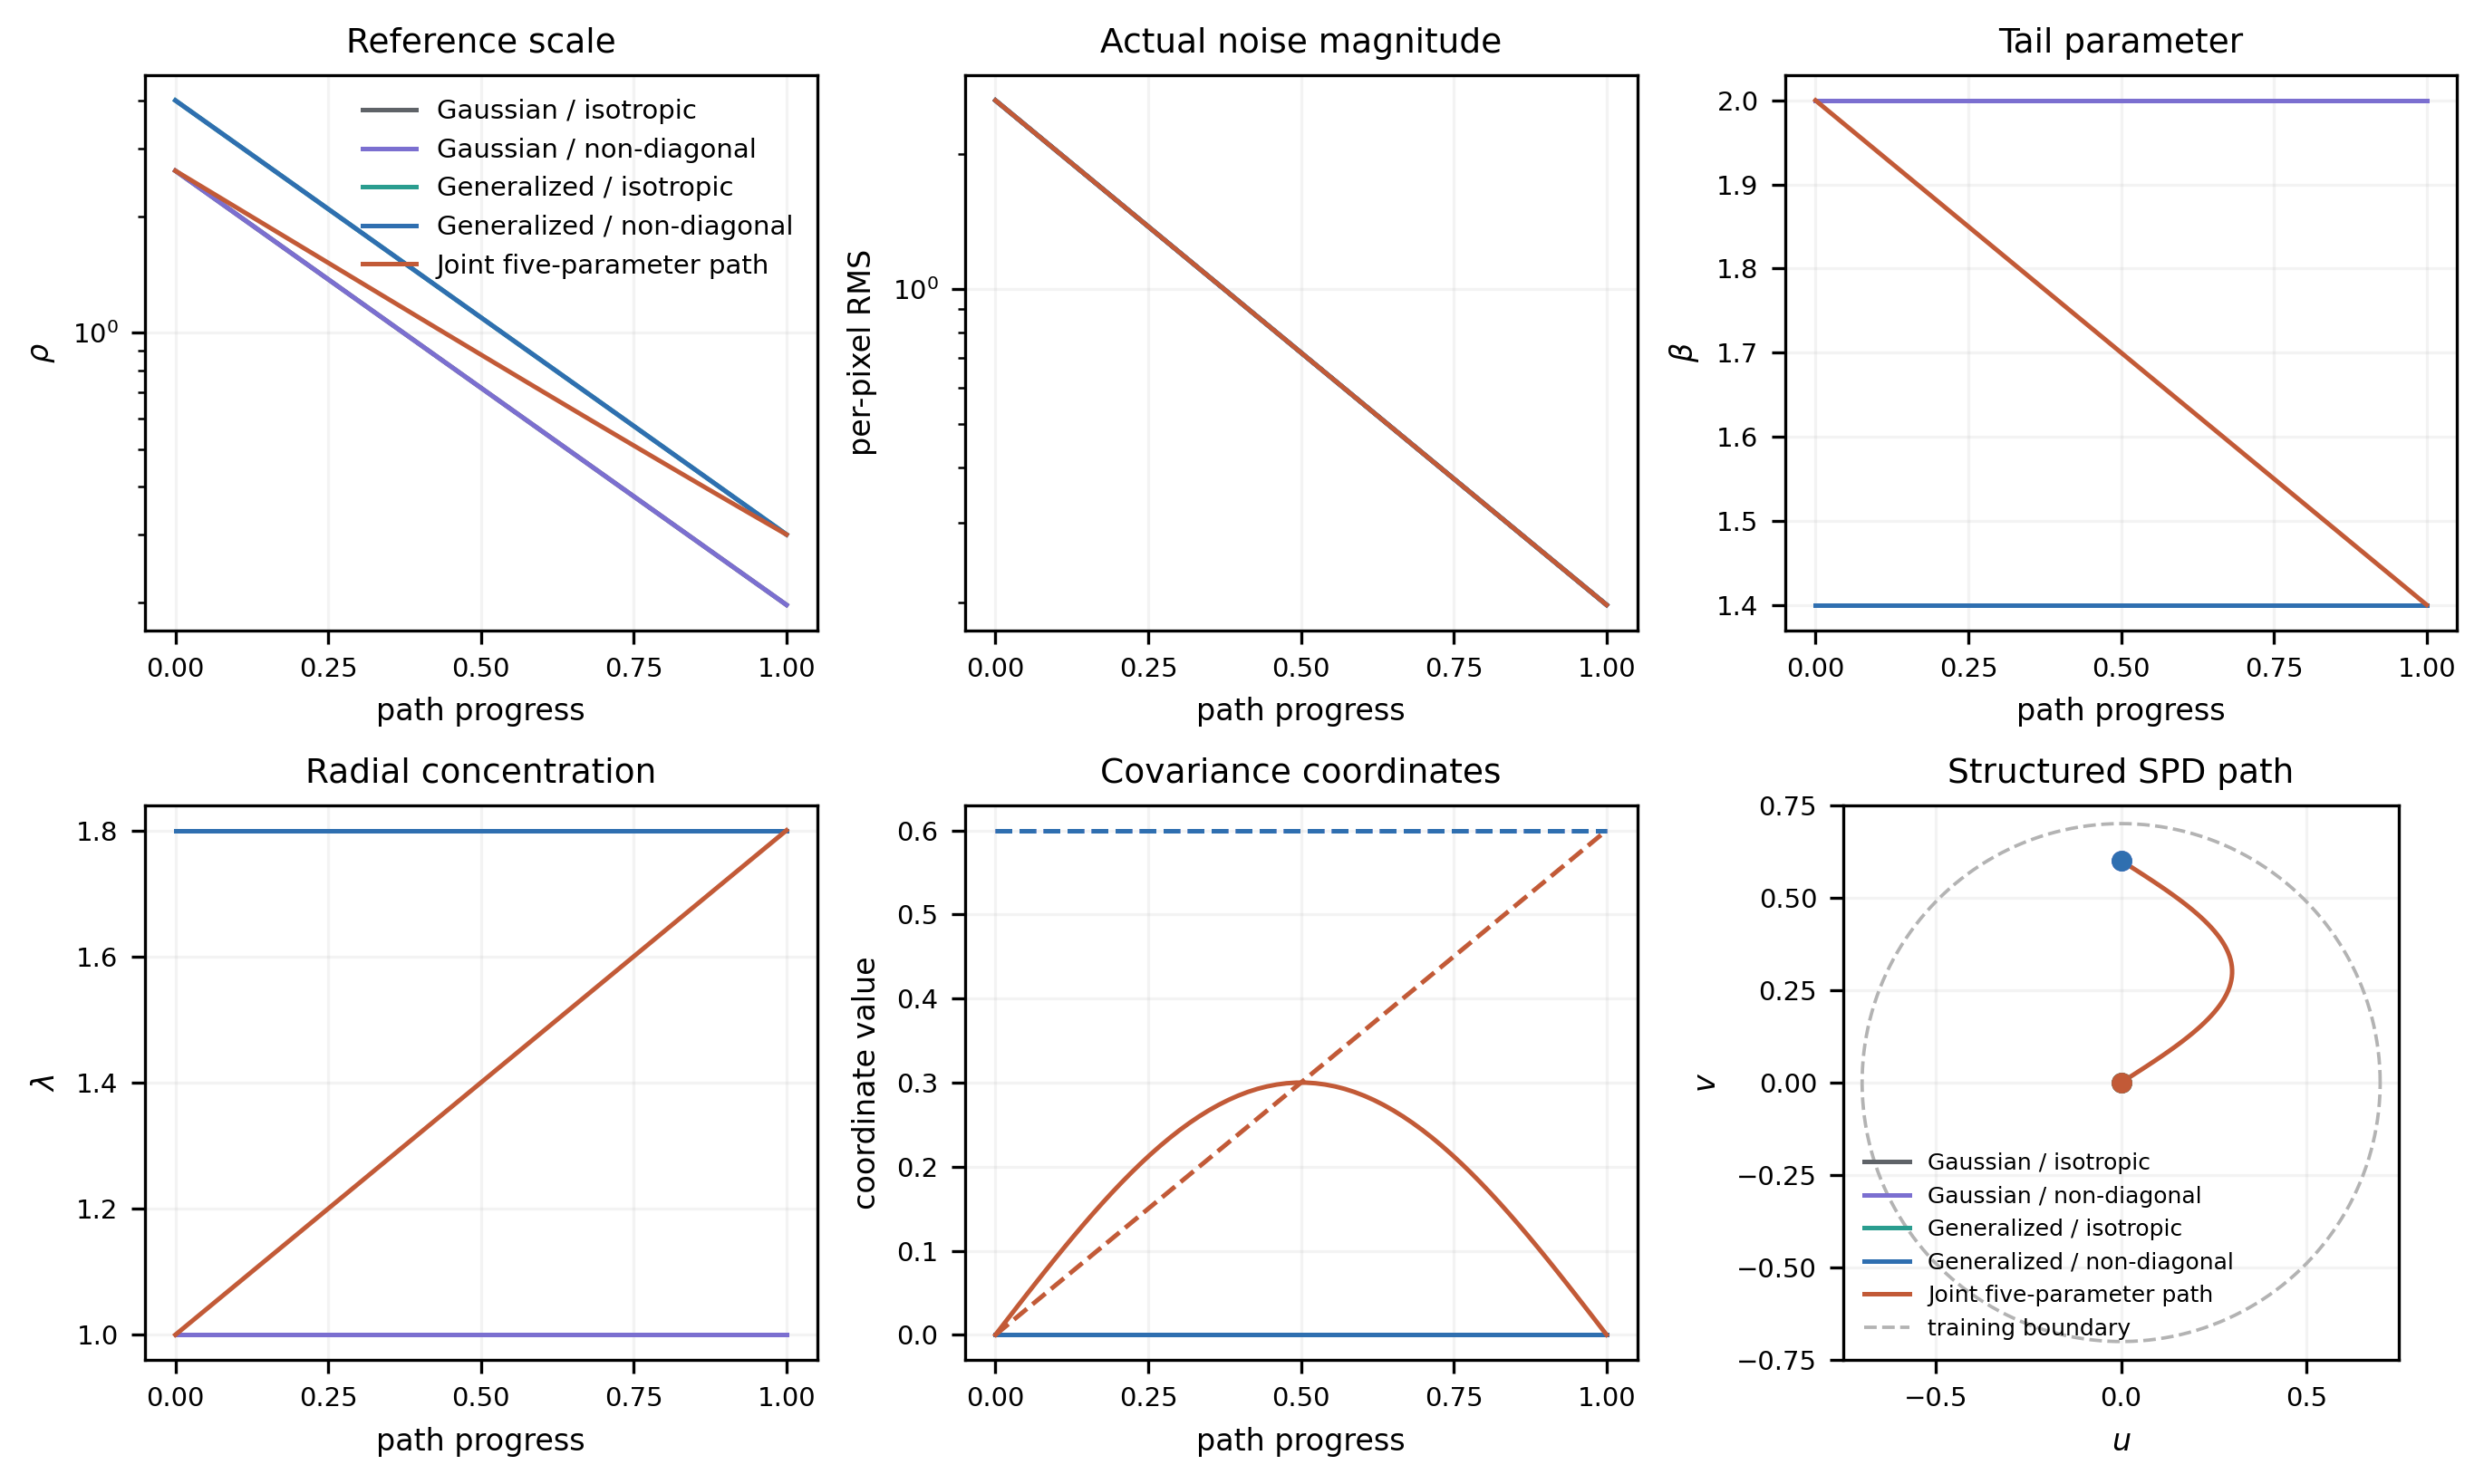

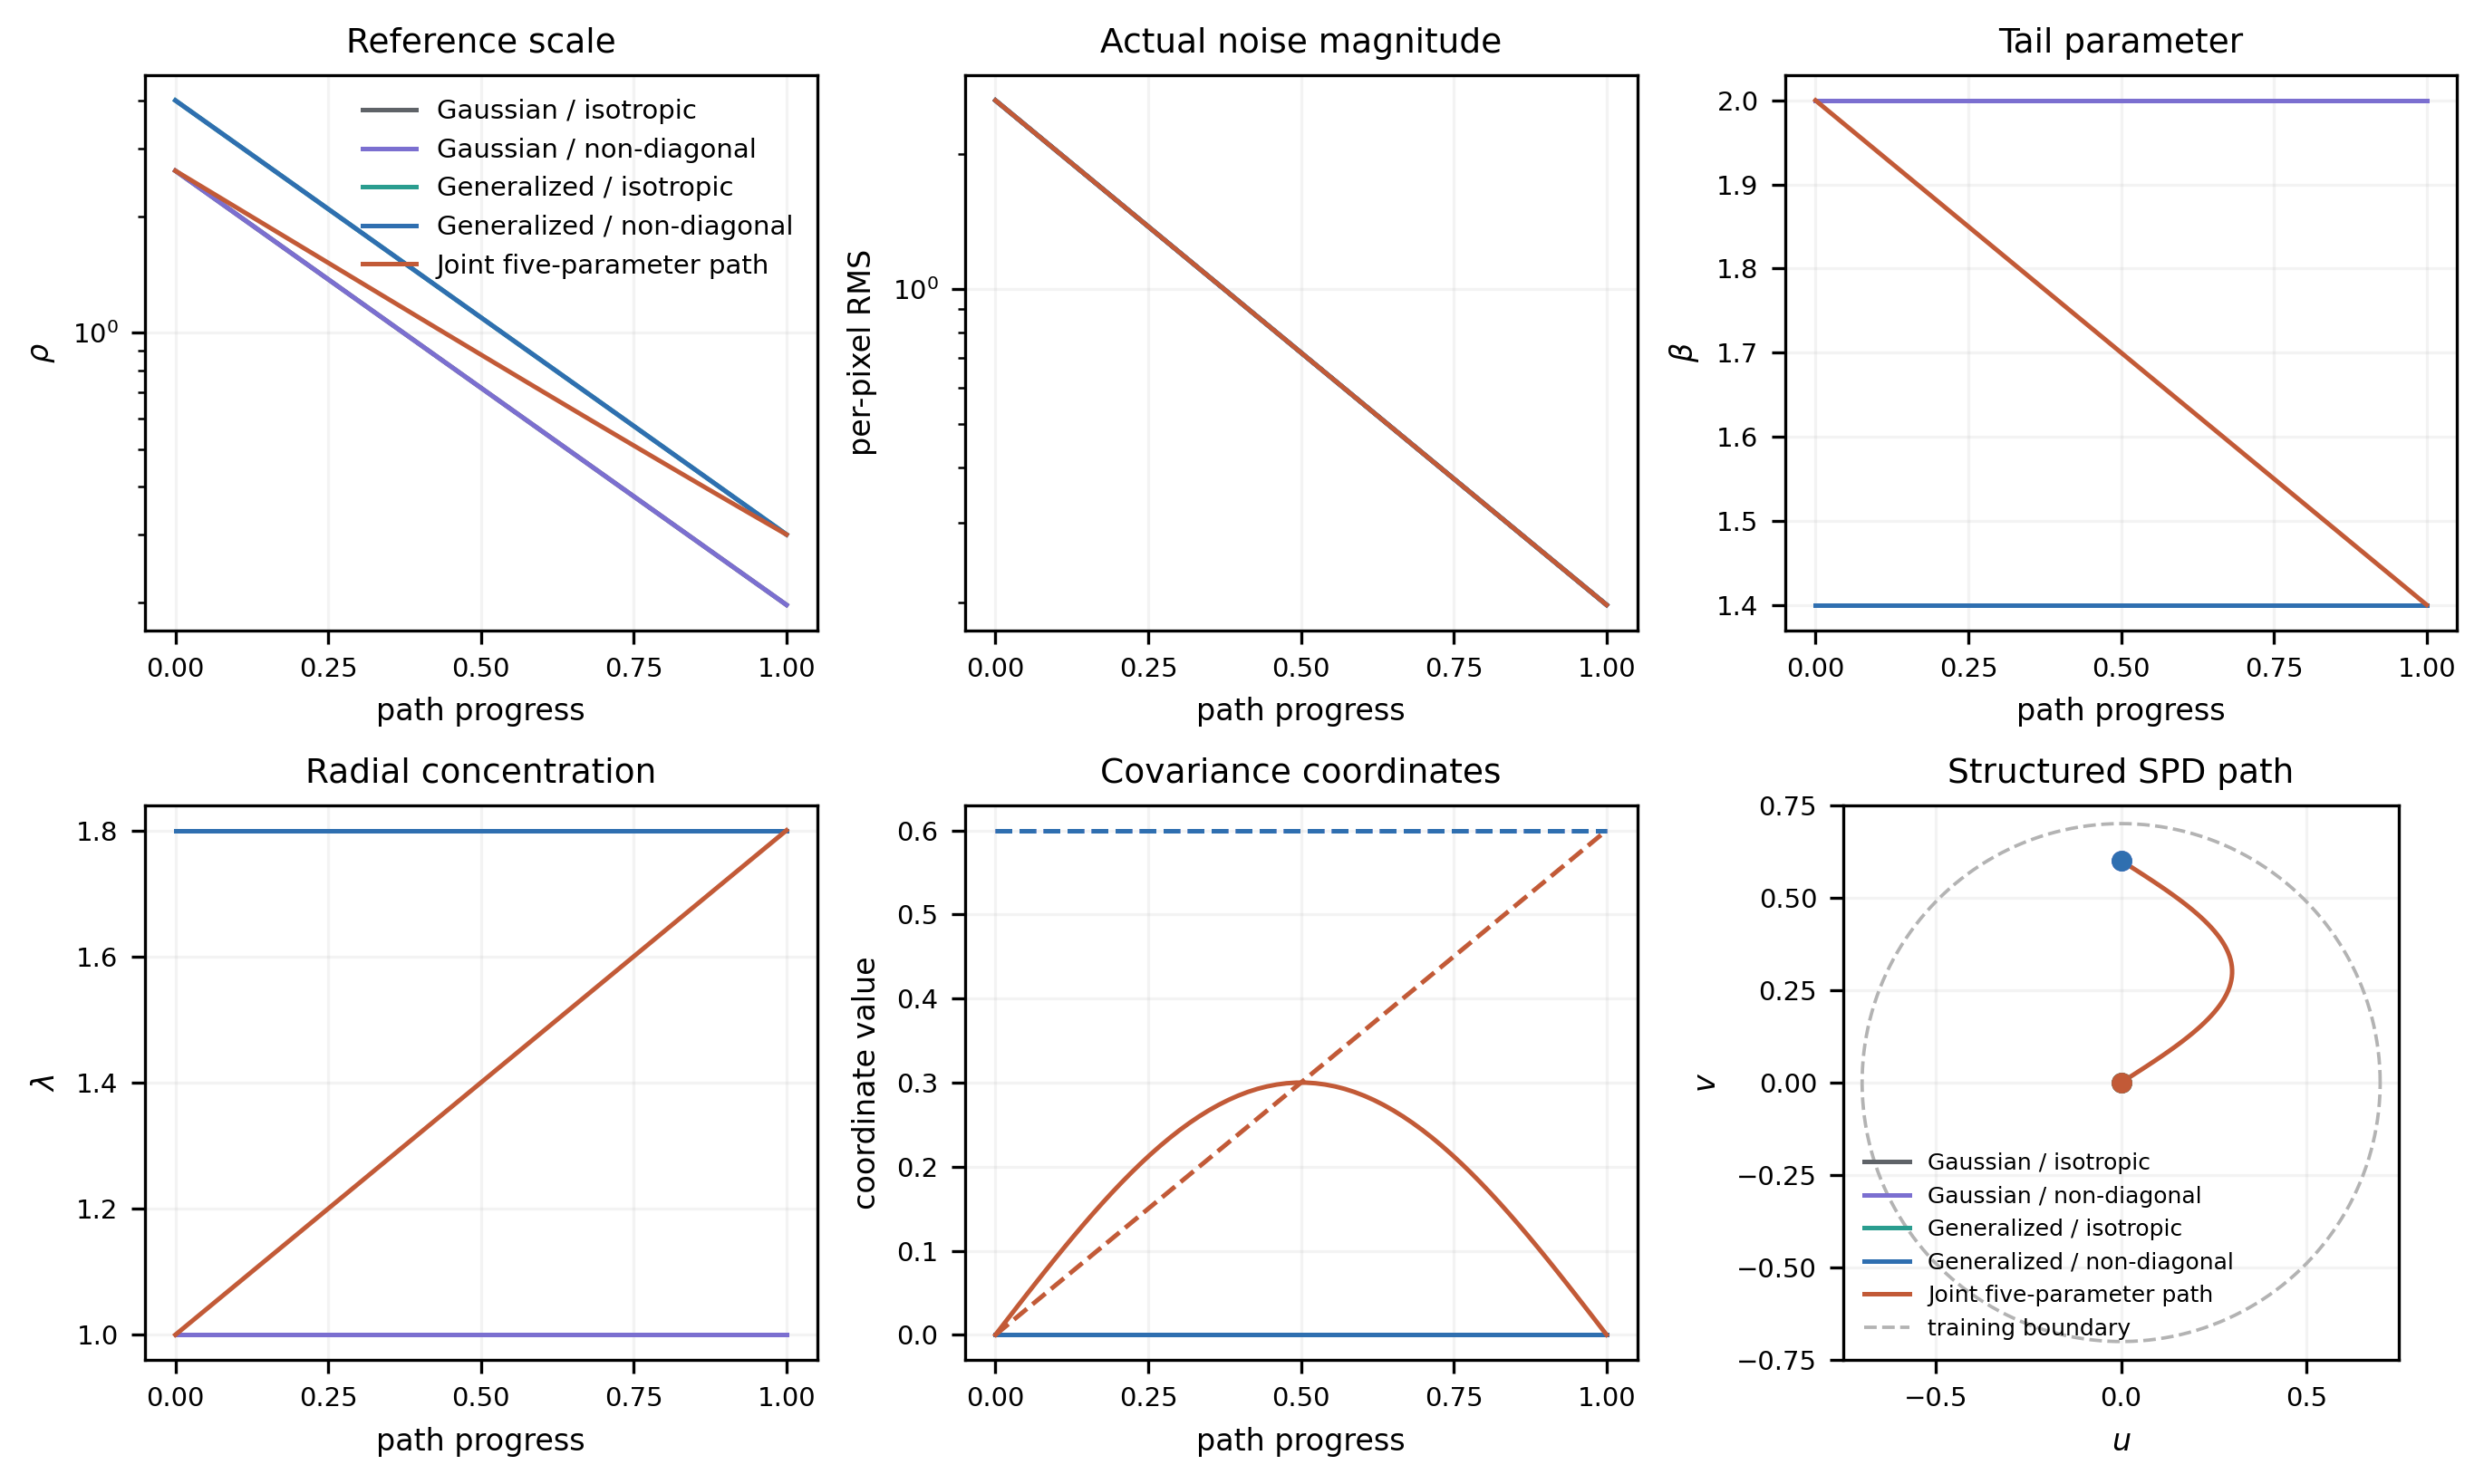

In [10]:
MNIST_PATH_PLOT_RC = {
    **MNIST_PLOT_RC,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "lines.linewidth": 1.6,
}
mnist_path_arrays = {
    path_name: {
        key: torch.as_tensor(schedule[key]).detach().cpu().numpy()
        for key in ("progress", "actual_rms", "rho", "beta", "lam", "u", "v")
    }
    for path_name, schedule in mnist_schedules.items()
}
mnist_path_progress = mnist_path_arrays["gaussian"]["progress"]
for path_arrays in mnist_path_arrays.values():
    np.testing.assert_allclose(path_arrays["progress"], mnist_path_progress)

mnist_radial_groups = [
    (["gaussian", "gaussian_non_diagonal"], "Gaussian (both geometries)", "0.35"),
    (
        ["generalized_isotropic", "fixed_non_diagonal"],
        "Generalized (both geometries)",
        MNIST_PATH_COLORS["fixed_non_diagonal"],
    ),
    (["joint"], "Joint", MNIST_PATH_COLORS["joint"]),
]
mnist_curve_panels = [
    (
        (0, 0),
        "Actual RMS",
        r"$r_t$ (per pixel)",
        [
            (
                [(name, "actual_rms") for name in MNIST_PATH_LABELS],
                "All paths",
                "0.25",
                "-",
            )
        ],
    ),
]
for position, key, title, symbol in [
    ((0, 1), "rho", "Reference RMS", r"$\rho_t$"),
    ((0, 2), "beta", "Tail shape", r"$\beta_t$"),
    ((1, 0), "lam", "Radial concentration", r"$\lambda_t$"),
]:
    mnist_curve_panels.append(
        (
            position,
            title,
            symbol,
            [
                ([(name, key) for name in names], label, color, "-")
                for names, label, color in mnist_radial_groups
            ],
        )
    )
mnist_curve_panels.append(
    (
        (1, 1),
        "Covariance coordinates",
        r"$u_t,\ v_t$",
        [
            (
                [(name, "u") for name in MNIST_PATH_LABELS if name != "joint"]
                + [("gaussian", "v"), ("generalized_isotropic", "v")],
                "$u$: all four fixed paths\n$v$: both isotropic paths",
                "0.35",
                ":",
            ),
            (
                [("gaussian_non_diagonal", "v"), ("fixed_non_diagonal", "v")],
                "$v$: both non-diagonal paths",
                MNIST_PATH_COLORS["fixed_non_diagonal"],
                "--",
            ),
            ([("joint", "u")], "$u$: joint", MNIST_PATH_COLORS["joint"], "-"),
            ([("joint", "v")], "$v$: joint", MNIST_PATH_COLORS["joint"], "--"),
        ],
    )
)

with plt.rc_context(MNIST_PATH_PLOT_RC):
    fig, axes = plt.subplots(2, 3, figsize=(9.6, 7.8), dpi=300, constrained_layout=True)
    for position, title, symbol, groups in mnist_curve_panels:
        axis = axes[position]
        for members, label, color, linestyle in groups:
            first_path, first_key = members[0]
            values = mnist_path_arrays[first_path][first_key]
            for path_name, key in members[1:]:
                np.testing.assert_allclose(
                    mnist_path_arrays[path_name][key],
                    values,
                    rtol=1e-6,
                    atol=1e-8,
                    err_msg=f"Coincident-curve group changed: {label}",
                )
            axis.plot(
                mnist_path_progress,
                values,
                color=color,
                linestyle=linestyle,
                label=label,
            )
        axis.set_title(title)
        axis.set_xlabel(r"Path progress $t$")
        axis.set_ylabel(symbol)
    axes[0, 0].set_yscale("log")
    axes[0, 1].set_yscale("log")

    joint = mnist_path_arrays["joint"]
    axes[1, 2].plot(
        joint["u"], joint["v"], color=MNIST_PATH_COLORS["joint"], label="Joint"
    )
    for names, label, color in [
        (["gaussian", "generalized_isotropic"], "Isotropic (both laws)", "0.35"),
        (
            ["gaussian_non_diagonal", "fixed_non_diagonal"],
            "Non-diagonal (both laws)",
            MNIST_PATH_COLORS["fixed_non_diagonal"],
        ),
    ]:
        representative = mnist_path_arrays[names[0]]
        for path_name in names:
            for key in ("u", "v"):
                np.testing.assert_allclose(
                    mnist_path_arrays[path_name][key],
                    representative[key][0],
                    rtol=1e-6,
                    atol=1e-8,
                )
        axes[1, 2].scatter(
            representative["u"][0],
            representative["v"][0],
            s=45,
            color=color,
            edgecolors="white",
            linewidths=0.7,
            zorder=5,
            label=label,
        )
    boundary_angle = np.linspace(0.0, 2.0 * np.pi, 400)
    axes[1, 2].plot(
        0.7 * np.cos(boundary_angle),
        0.7 * np.sin(boundary_angle),
        color="0.7",
        linestyle="--",
        linewidth=0.9,
        label="Training boundary",
    )
    axes[1, 2].set_title("Covariance path")
    axes[1, 2].set_xlabel(r"$u$")
    axes[1, 2].set_ylabel(r"$v$")
    axes[1, 2].set_aspect("equal")
    axes[1, 2].set_xlim(-0.75, 0.75)
    axes[1, 2].set_ylim(-0.75, 0.75)

    for axis in axes.flat:
        axis.grid(alpha=0.18)
        axis.legend(
            frameon=False,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.28),
            borderaxespad=0,
            handlelength=1.8,
            labelspacing=0.3,
        )
    fig.savefig(MNIST_FIG_DIR / "mnist_parameter_paths.png", bbox_inches="tight")
    fig.savefig(MNIST_FIG_DIR / "mnist_parameter_paths.pdf", bbox_inches="tight")


# Load the production bundles

The five configurations produce two 128-image chunks for each of the three generation seeds. Load these chunks and check their sampler settings and schedules before pooling the images.


In [11]:
mnist_final_batches = {}
mnist_batch_rows = []
for path_name in MNIST_PATH_LABELS:
    for generation_seed in MNIST_GENERATION_SEEDS:
        chunk_finals = []
        for chunk_index in range(PRODUCTION_CHUNKS):
            bundle_file = mnist_production_bundle_path(
                path_name, generation_seed, chunk_index
            )
            if not bundle_file.is_file():
                raise FileNotFoundError(f"Missing production bundle: {bundle_file}")
            payload = torch.load(bundle_file, map_location="cpu", weights_only=False)
            metadata = payload.get("metadata", {})
            expectations = {
                "run_name": MNIST_PRODUCTION_RUN_NAME,
                "path": path_name,
                "generation_seed": int(generation_seed),
                "chunk_index": int(chunk_index),
                "sampler": MNIST_PRODUCTION_SAMPLER_CONFIG,
            }
            for key, expected in expectations.items():
                if metadata.get(key) != expected:
                    raise RuntimeError(
                        f"Bundle metadata mismatch for {bundle_file}: {key}={metadata.get(key)!r} != {expected!r}"
                    )
            observed_schedule = metadata.get("schedule")
            if not isinstance(observed_schedule, dict):
                raise RuntimeError(f"Bundle schedule is unavailable: {bundle_file}")
            for field, expected_values in mnist_schedules[path_name].items():
                if field not in observed_schedule:
                    raise RuntimeError(
                        f"Bundle schedule field {field!r} is unavailable: {bundle_file}"
                    )
                observed_values = torch.as_tensor(observed_schedule[field]).float()
                expected_values = torch.as_tensor(expected_values).cpu().float()
                schedule_rtol = 0.0005 if field == "sigma" else 1e-06
                if (
                    observed_values.shape != expected_values.shape
                    or not torch.allclose(
                        observed_values, expected_values, atol=1e-06, rtol=schedule_rtol
                    )
                ):
                    raise RuntimeError(
                        f"Bundle schedule mismatch for {bundle_file}: {field}"
                    )
            chunk_finals.append(torch.as_tensor(payload["final"]).float())
        batch = torch.cat(chunk_finals)
        mnist_final_batches[path_name, int(generation_seed)] = batch
        mnist_batch_rows.append(
            {
                "path": path_name,
                "generation_seed": int(generation_seed),
                "n_samples": len(batch),
            }
        )
mnist_metrics_df = (
    pd.DataFrame(mnist_batch_rows)
    .sort_values(["path", "generation_seed"])
    .reset_index(drop=True)
)
mnist_samples_per_seed = int(mnist_metrics_df["n_samples"].iloc[0])
if mnist_metrics_df["n_samples"].nunique() != 1:
    raise RuntimeError("Seed batches have unequal sizes")
print(
    f"Loaded {len(mnist_final_batches)} seed batches of {mnist_samples_per_seed} images each."
)
mnist_metrics_df


Loaded 15 seed batches of 256 images each.


,path,generation_seed,n_samples,final_mean,final_std,mean_active_pixels,mean_pixelwise_sample_std,mean_pairwise_l2
0,fixed_non_diagonal,2718,256,0.119018,0.291134,124.257812,0.175014,9.549381
1,fixed_non_diagonal,3141,256,0.119970,0.293679,123.523438,0.174906,9.586284
2,fixed_non_diagonal,5772,256,0.115202,0.287519,119.843750,0.169451,9.362318
3,gaussian,2718,256,0.105022,0.271863,112.222656,0.164956,9.002869
4,gaussian,3141,256,0.103419,0.270352,110.585938,0.161815,8.923983
5,gaussian,5772,256,0.100927,0.266850,108.156250,0.159958,8.791308
6,gaussian_non_diagonal,2718,256,0.117919,0.288080,124.210938,0.175111,9.498100
7,gaussian_non_diagonal,3141,256,0.120257,0.292695,125.039062,0.176241,9.564402
8,gaussian_non_diagonal,5772,256,0.114937,0.285944,120.359375,0.169311,9.325260
9,generalized_isotropic,2718,256,0.102814,0.271457,107.933594,0.164700,8.979834


# Final samples by path

Each panel shows the first 16 unselected endpoint images from seed 2718, using the same model checkpoint under a different path.


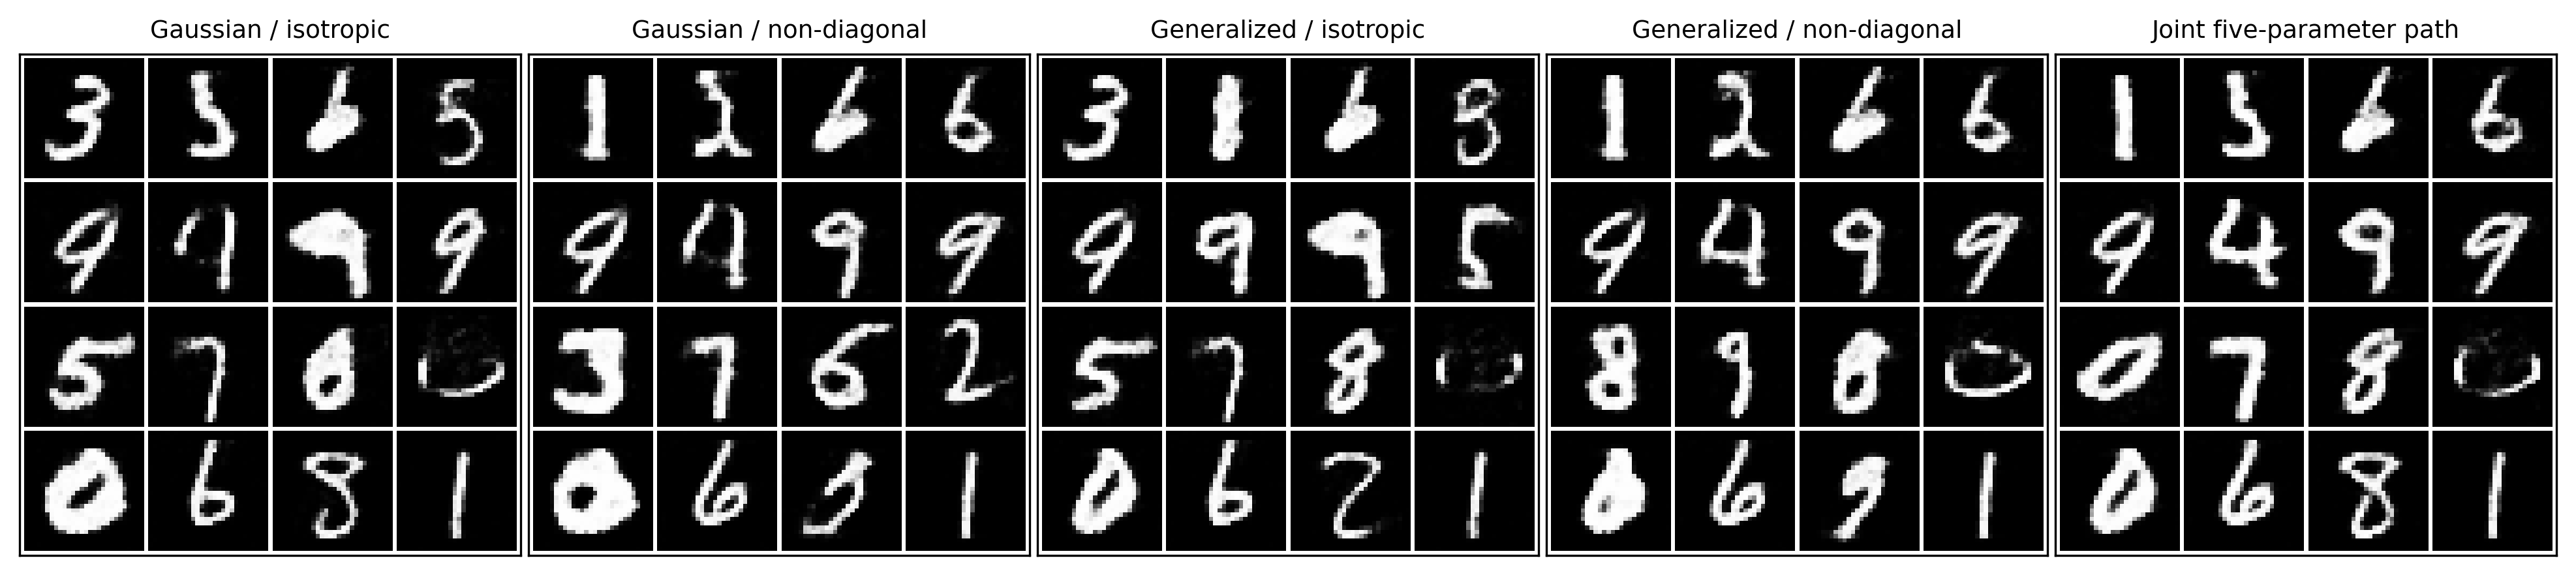

In [14]:
with plt.rc_context(MNIST_PLOT_RC):
    fig, axes = plt.subplots(
        1,
        len(MNIST_PATH_LABELS),
        figsize=(13.2, 3.2),
        dpi=300,
    )
    for column_index, path_name in enumerate(MNIST_PATH_LABELS):
        batch = mnist_final_batches[(path_name, MNIST_FIGURE_SEED)]
        grid = make_mnist_image_grid(
            batch[:16].clamp(0.0, 1.0),
            nrow=4,
            padding=1,
        )
        axis = axes[column_index]
        axis.imshow(grid.permute(1, 2, 0).numpy(), vmin=0.0, vmax=1.0)
        axis.set_xticks([])
        axis.set_yticks([])
        axis.set_title(MNIST_PATH_LABELS[path_name])
    fig.tight_layout(w_pad=0.35)
    fig.savefig(
        MNIST_FIG_DIR / "mnist_final_samples_by_path.png",
        bbox_inches="tight",
    )
    fig.savefig(
        MNIST_FIG_DIR / "mnist_final_samples_by_path.pdf",
        bbox_inches="tight",
    )


## Path-to-path stability across generation seeds

Rows change the parameter path and columns change the sampler's random seed for initialization, posterior Monte Carlo draws, and Langevin noise. Every panel uses the first endpoint samples from that run.


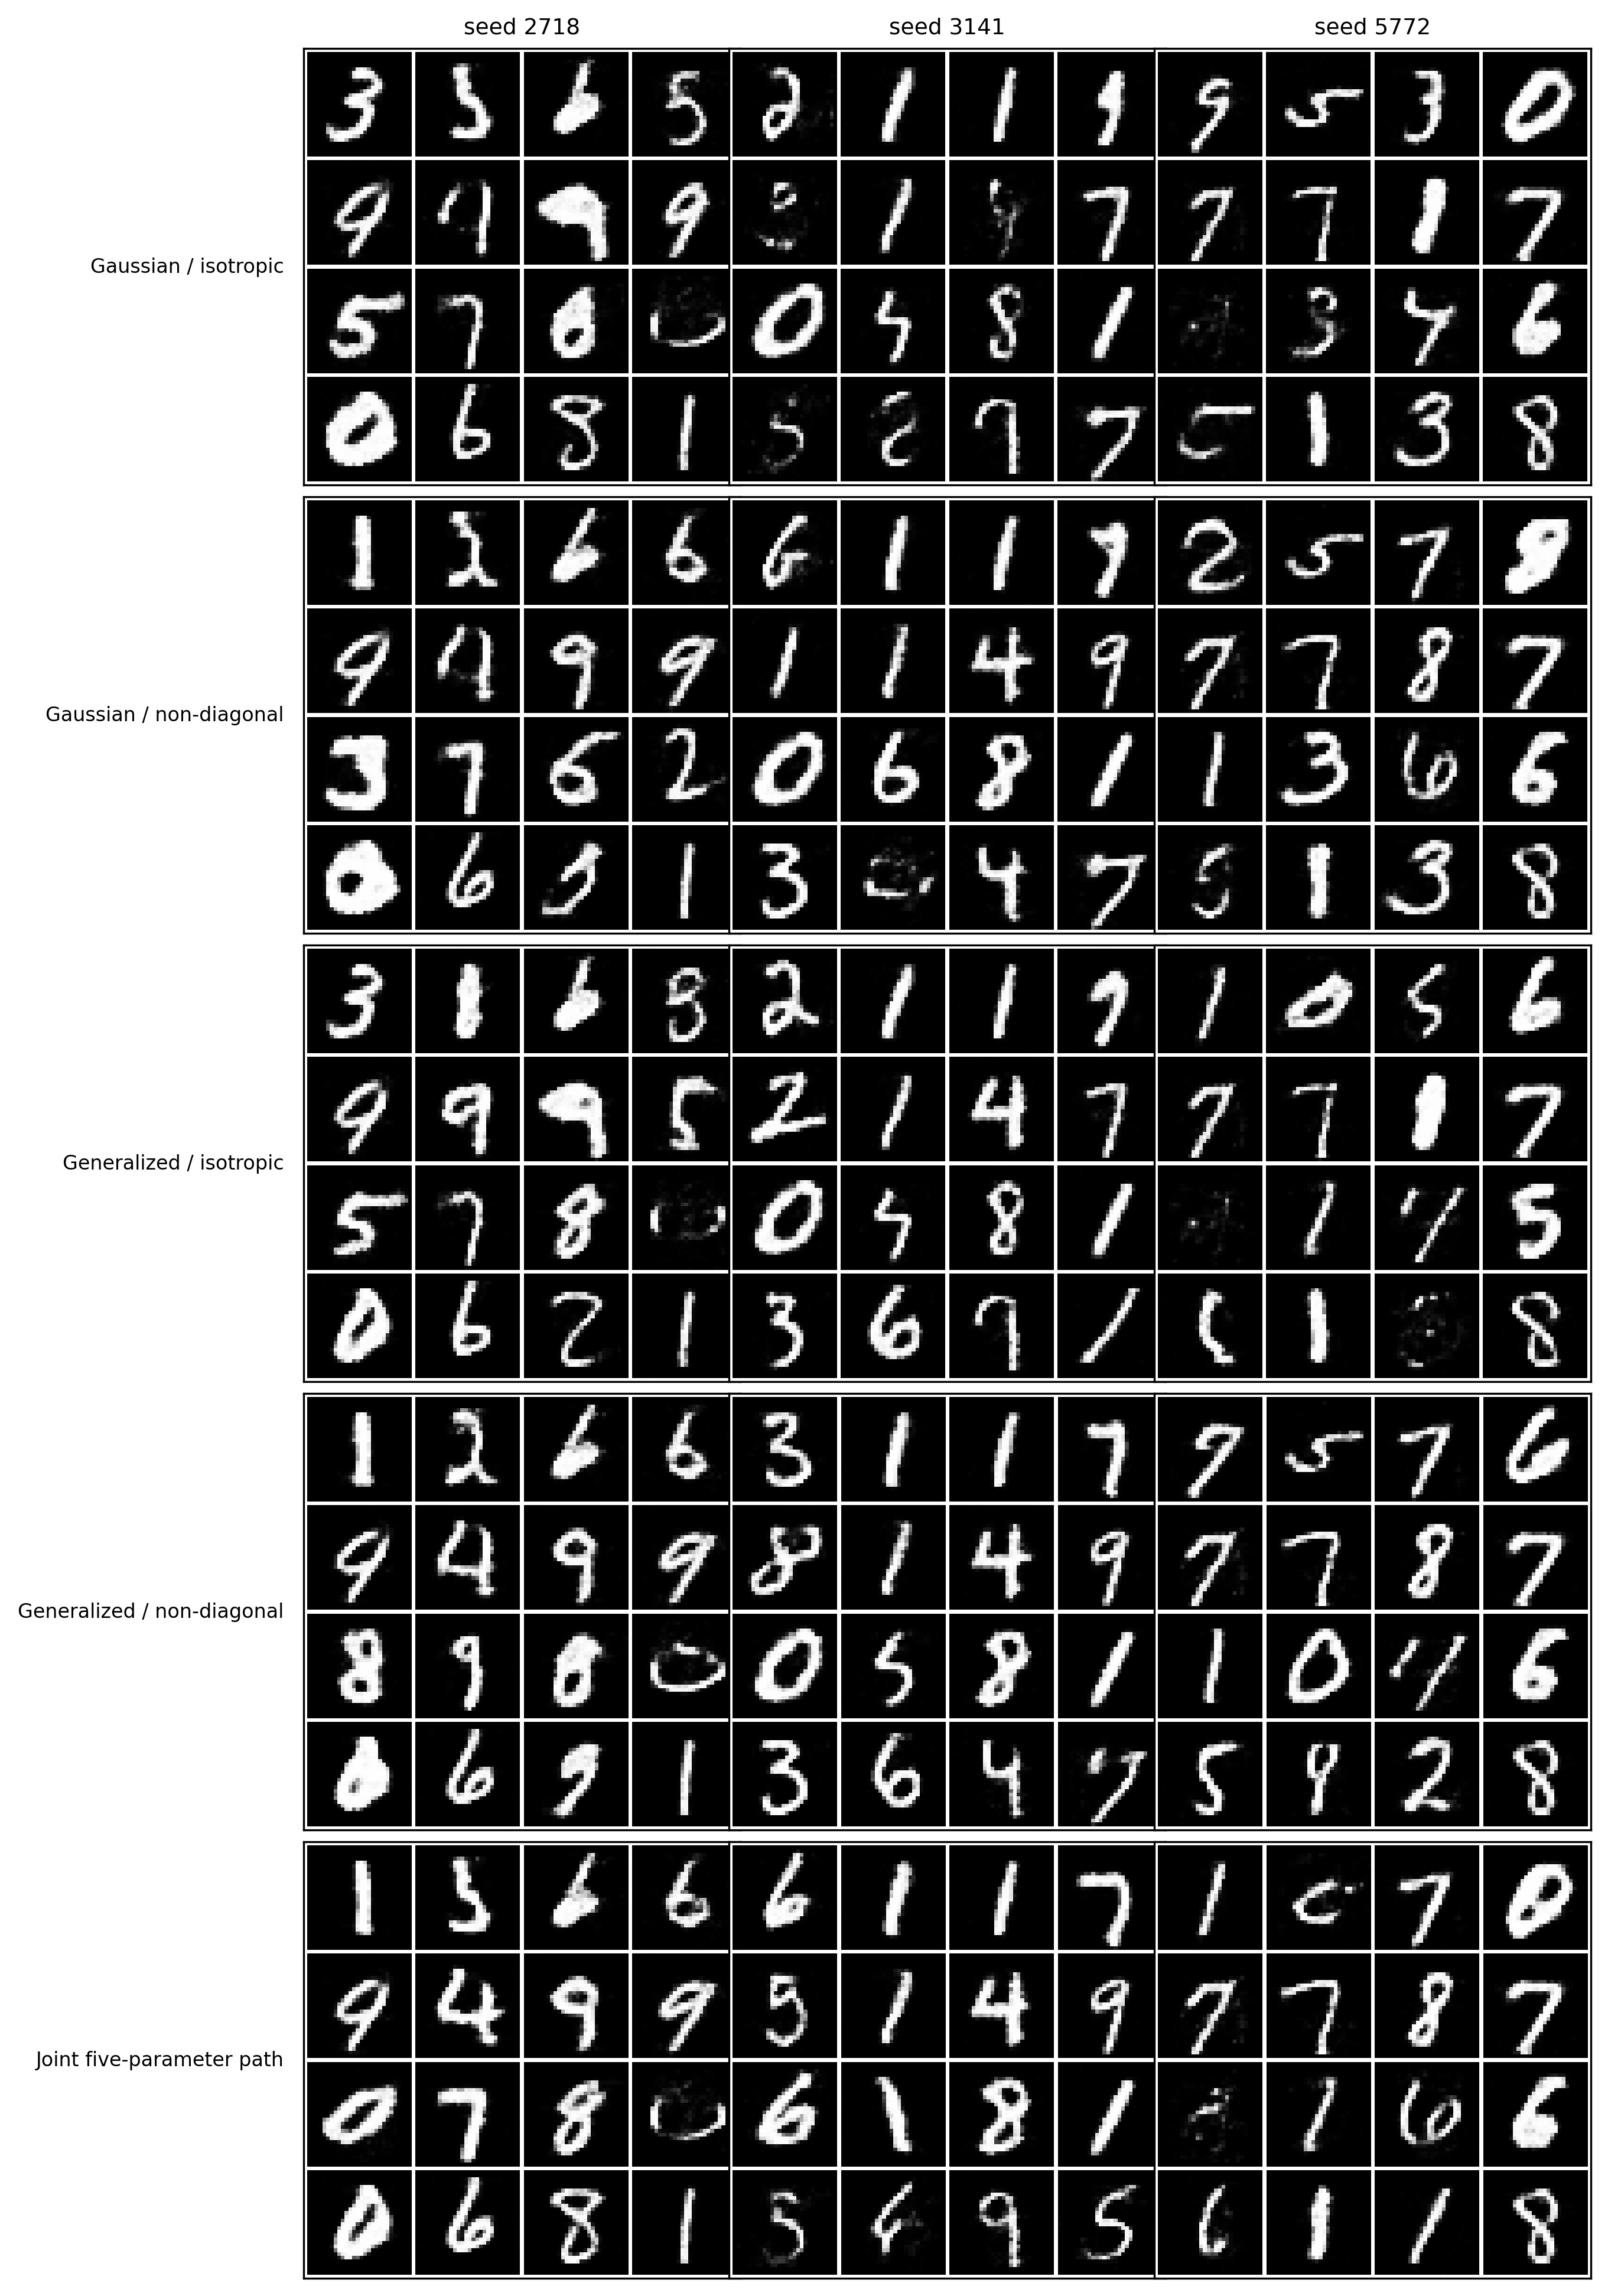

In [15]:
with plt.rc_context(MNIST_PLOT_RC):
    fig, axes = plt.subplots(
        len(MNIST_PATH_LABELS),
        len(MNIST_GENERATION_SEEDS),
        figsize=(9.2, 13.0),
        dpi=300,
    )
    for row_index, path_name in enumerate(MNIST_PATH_LABELS):
        for column_index, generation_seed in enumerate(MNIST_GENERATION_SEEDS):
            axis = axes[row_index, column_index]
            batch = mnist_final_batches[(path_name, int(generation_seed))]
            grid = make_mnist_image_grid(
                batch[:16].clamp(0.0, 1.0),
                nrow=4,
                padding=1,
            )
            axis.imshow(grid.permute(1, 2, 0).numpy(), vmin=0.0, vmax=1.0)
            axis.set_xticks([])
            axis.set_yticks([])
            if row_index == 0:
                axis.set_title(f"seed {generation_seed}")
            if column_index == 0:
                axis.set_ylabel(
                    MNIST_PATH_LABELS[path_name],
                    fontsize=8,
                    rotation=0,
                    ha="right",
                    va="center",
                    labelpad=8,
                )

    fig.tight_layout(w_pad=0.35, h_pad=0.6)
    fig.savefig(
        MNIST_FIG_DIR / "mnist_path_comparison_across_seeds.png",
        bbox_inches="tight",
    )
    fig.savefig(
        MNIST_FIG_DIR / "mnist_path_comparison_across_seeds.pdf",
        bbox_inches="tight",
    )


# Same-chain generation progress at matched actual RMS

Each column follows the same nine saved chains under one path for the production checkpoint, with abbreviated path labels across the top. Intermediate rows are selected by actual per-pixel RMS, rather than by a common path index, so every row compares the five paths at a matched corruption magnitude. Each cell displays the chains as a $3\times3$ grid. The first row is the path-matched initial noise and the last row is the final posterior draw.

In [38]:
mnist_progress_paths = list(MNIST_PATH_LABELS)
MNIST_LABELS_SHORT = {
    "gaussian": "Gauss",
    "gaussian_non_diagonal": "Gauss-aniso",
    "generalized_isotropic": "Gen-iso",
    "fixed_non_diagonal": "Gen",
    "joint": "Joint",
}
mnist_progress_payloads = {
    path_name: torch.load(
        mnist_production_bundle_path(path_name, MNIST_FIGURE_SEED, 0),
        map_location="cpu",
        weights_only=False,
    )
    for path_name in mnist_progress_paths
}
mnist_progress_schedules = {
    path_name: {
        key: torch.as_tensor(value)
        for key, value in payload["metadata"]["schedule"].items()
    }
    for path_name, payload in mnist_progress_payloads.items()
}

for path_name in mnist_progress_paths:
    trajectory = mnist_progress_payloads[path_name]["trajectory"]
    schedule = mnist_progress_schedules[path_name]
    if len(trajectory) != len(schedule["actual_rms"]) + 1:
        raise RuntimeError(
            f"Unexpected trajectory length for {path_name}: "
            f"{len(trajectory)} versus {len(schedule['actual_rms']) + 1}"
        )

mnist_progress_rms_targets = np.geomspace(RMS_START, RMS_END, 6)[1:-1]


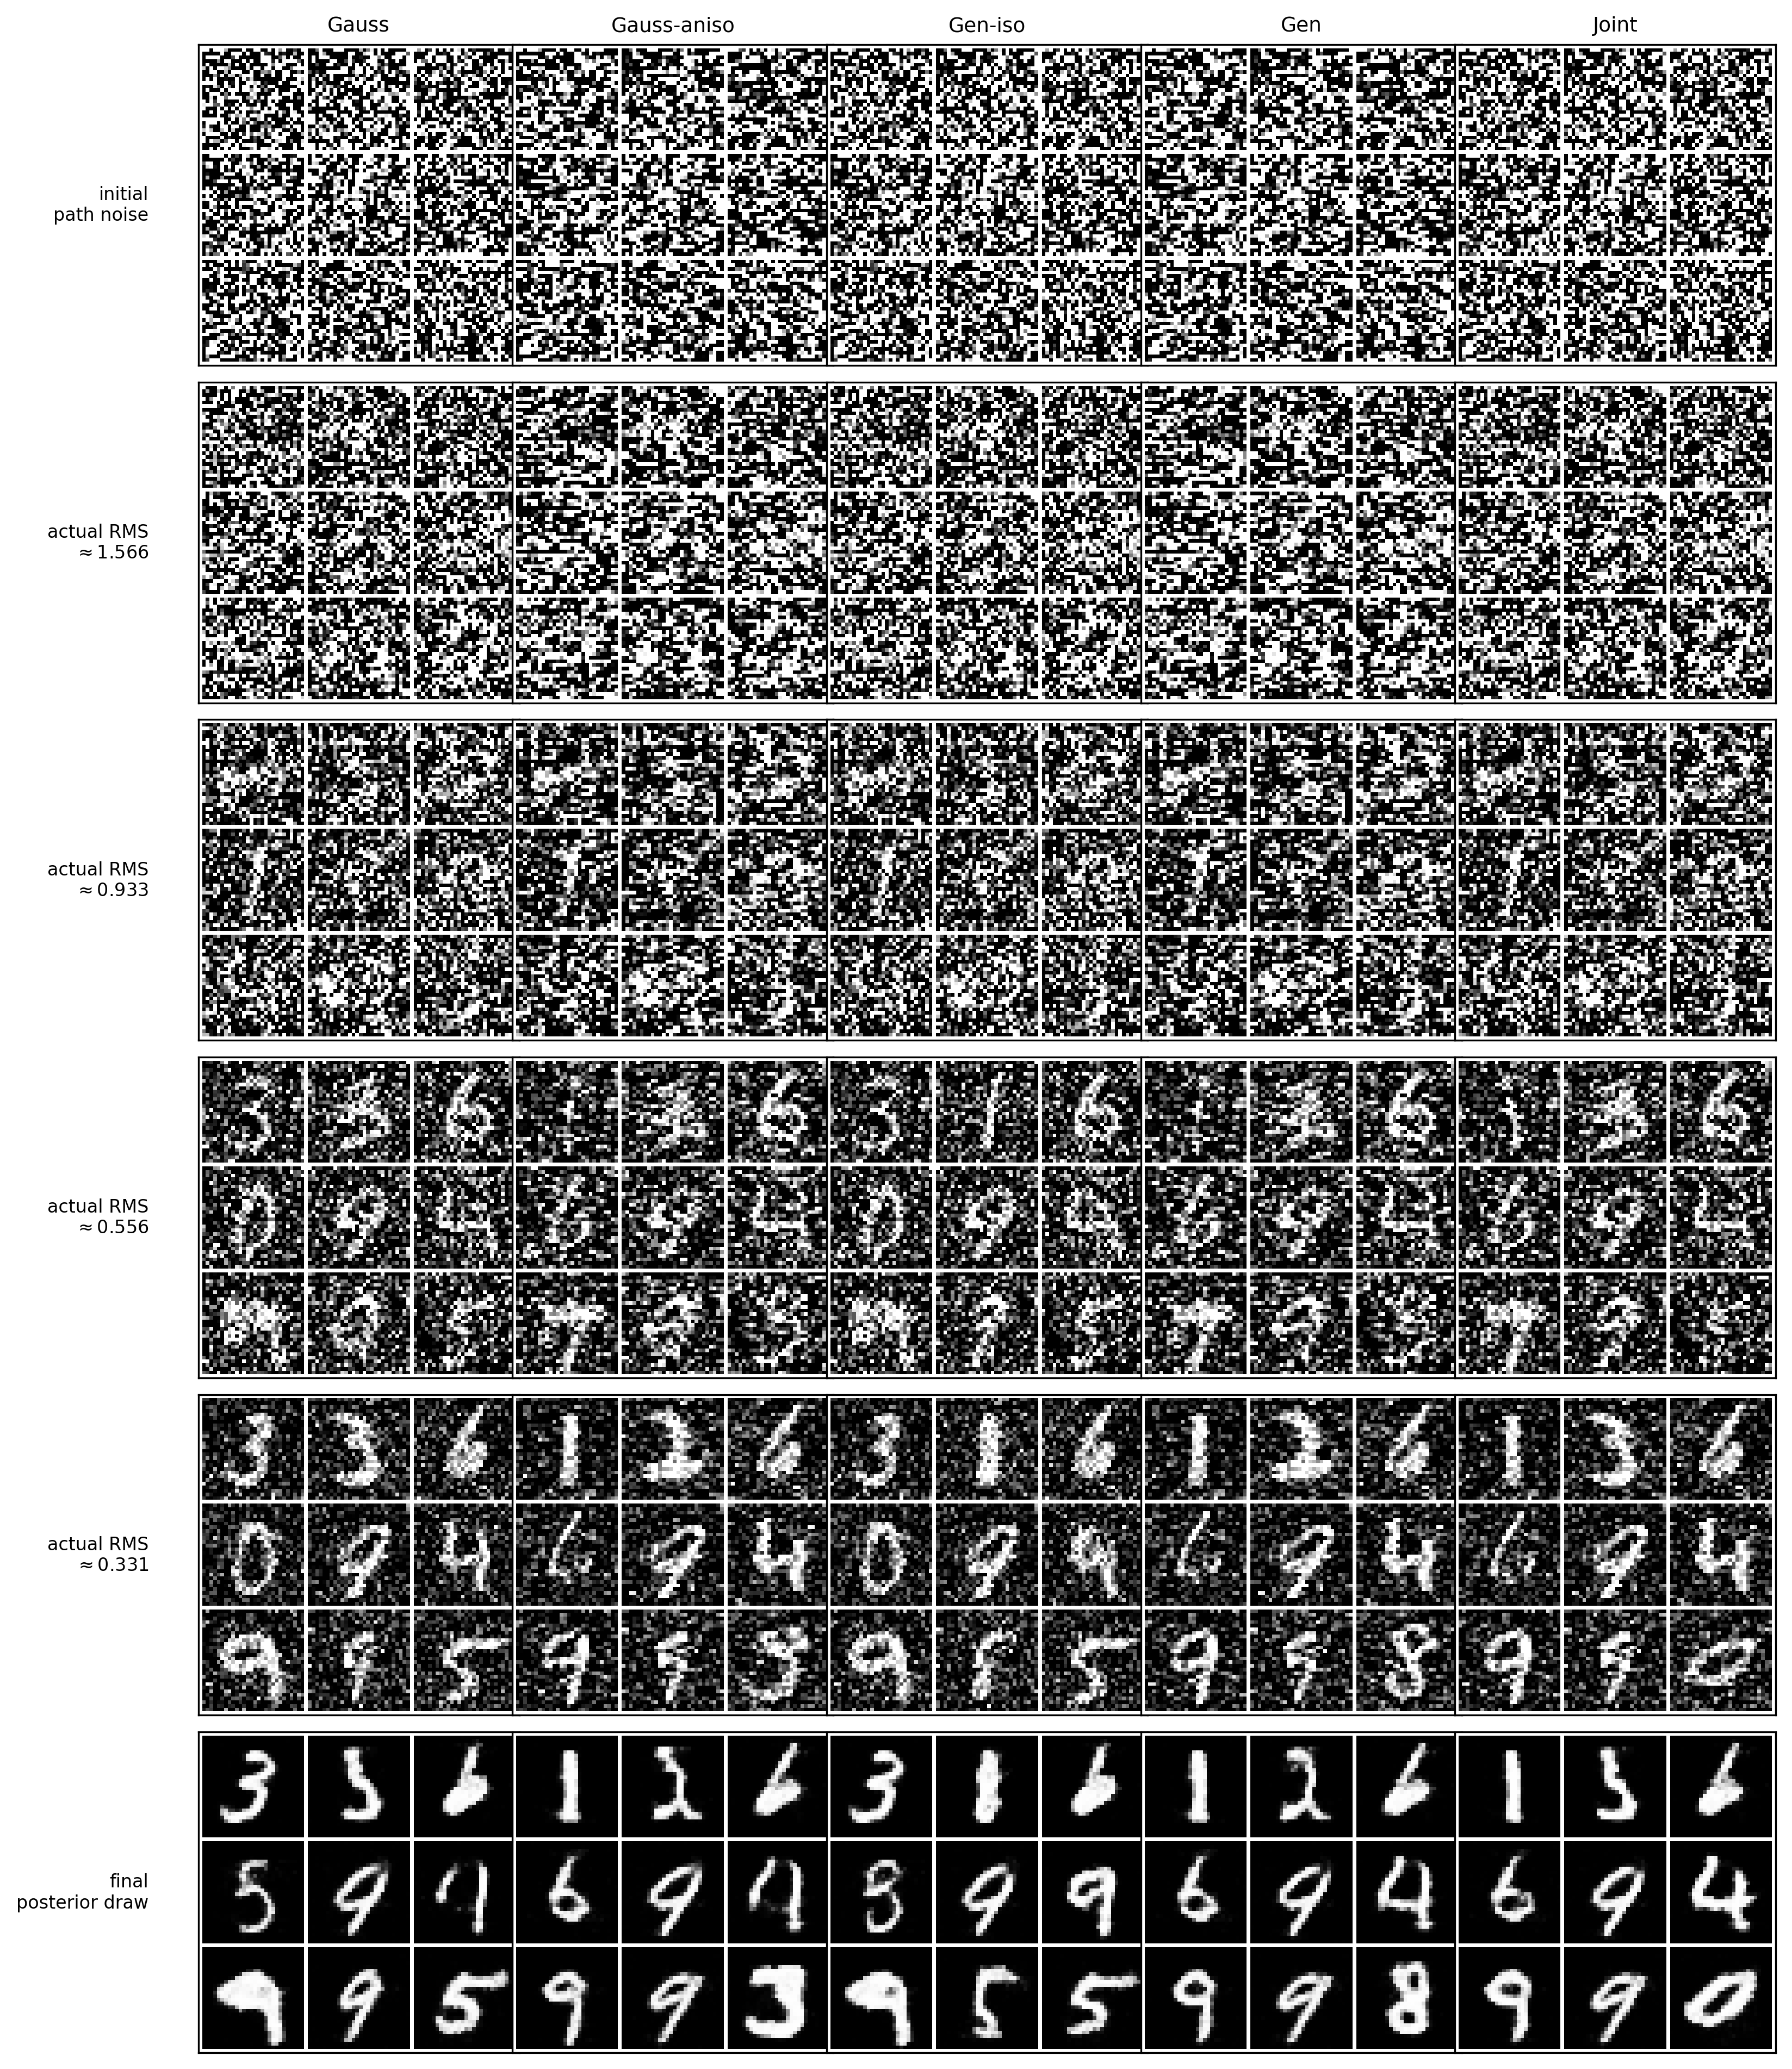

In [40]:
MNIST_PROGRESS_GRID_SIDE = 3
MNIST_PROGRESS_IMAGES_PER_CELL = MNIST_PROGRESS_GRID_SIDE**2
mnist_progress_stage_count = len(mnist_progress_rms_targets) + 2

with plt.rc_context(MNIST_PLOT_RC):
    fig, axes = plt.subplots(
        mnist_progress_stage_count,
        len(mnist_progress_paths),
        figsize=(10.8, 12.6),
        dpi=300,
    )
    for column_index, path_name in enumerate(mnist_progress_paths):
        payload = mnist_progress_payloads[path_name]
        schedule = mnist_progress_schedules[path_name]
        trajectory = payload["trajectory"]
        states = [torch.as_tensor(trajectory[0])]

        for target_rms in mnist_progress_rms_targets:
            level_index = int(
                (schedule["actual_rms"] - float(target_rms)).abs().argmin()
            )
            states.append(torch.as_tensor(trajectory[level_index + 1]))

        states.append(torch.as_tensor(payload["final"]))

        for row_index, state in enumerate(states):
            if len(state) < MNIST_PROGRESS_IMAGES_PER_CELL:
                raise RuntimeError(
                    f"Progress state for {path_name} contains {len(state)} "
                    f"images; expected at least {MNIST_PROGRESS_IMAGES_PER_CELL}."
                )
            axis = axes[row_index, column_index]
            grid = make_mnist_image_grid(
                state[:MNIST_PROGRESS_IMAGES_PER_CELL].float().clamp(0.0, 1.0),
                nrow=MNIST_PROGRESS_GRID_SIDE,
                padding=1,
            )
            axis.imshow(grid.permute(1, 2, 0).numpy(), vmin=0.0, vmax=1.0)
            axis.set_xticks([])
            axis.set_yticks([])
            if row_index == 0:
                axis.set_title(MNIST_LABELS_SHORT[path_name], fontsize=16, pad=6)
            if column_index == 0:
                if row_index == 0:
                    stage_label = "initial\npath noise"
                elif row_index == len(states) - 1:
                    stage_label = "final\nposterior draw"
                else:
                    stage_label = (
                        "actual RMS\n"
                        rf"$\approx {mnist_progress_rms_targets[row_index - 1]:.3f}$"
                    )
                axis.set_ylabel(
                    stage_label,
                    rotation=0,
                    ha="right",
                    va="center",
                    fontsize=15,
                    labelpad=22,
                )

    fig.tight_layout(pad=0.2, w_pad=0.15, h_pad=0.3)
    fig.savefig(
        MNIST_FIG_DIR / "mnist_generation_progress_by_path.png",
        bbox_inches="tight",
    )
    fig.savefig(
        MNIST_FIG_DIR / "mnist_generation_progress_by_path.pdf",
        bbox_inches="tight",
    )


# Nearest training images

The first 12 samples from every production path at seed 2718 are clipped to the image range and paired with their nearest MNIST training images in raw pixel-space Euclidean distance. This applies the same lightweight memorization check to the complete path package. Raw pixel distance is not a perceptual similarity metric.

In [ ]:
mnist_training_dataset = MNISTUint8Dataset(
    ROOT / "data",
    train=True,
    download=True,
)
mnist_training_vectors = (
    mnist_training_dataset.data.reshape(-1, MNIST_DIM).float() / 255.0
)


In [ ]:
mnist_neighbor_paths = list(MNIST_PATH_LABELS)
mnist_neighbors_per_path = 12
mnist_neighbor_queries_by_path = {
    path_name: mnist_final_batches[(path_name, MNIST_FIGURE_SEED)][
        :mnist_neighbors_per_path
    ]
    .float()
    .clamp(0.0, 1.0)
    for path_name in mnist_neighbor_paths
}
mnist_neighbor_queries = torch.cat(
    [mnist_neighbor_queries_by_path[path_name] for path_name in mnist_neighbor_paths]
).to(MNIST_DEVICE)
mnist_neighbor_distances = torch.full(
    (mnist_neighbor_queries.shape[0],),
    float("inf"),
    device=MNIST_DEVICE,
)
mnist_neighbor_indices = torch.full(
    (mnist_neighbor_queries.shape[0],),
    -1,
    dtype=torch.long,
    device=MNIST_DEVICE,
)
mnist_neighbor_chunk_size = 2048

for start in range(0, len(mnist_training_vectors), mnist_neighbor_chunk_size):
    stop = min(start + mnist_neighbor_chunk_size, len(mnist_training_vectors))
    training_chunk = mnist_training_vectors[start:stop].to(MNIST_DEVICE)
    distances = torch.cdist(mnist_neighbor_queries, training_chunk)
    chunk_distances, chunk_indices = distances.min(dim=1)
    improved = chunk_distances < mnist_neighbor_distances
    mnist_neighbor_distances[improved] = chunk_distances[improved]
    mnist_neighbor_indices[improved] = start + chunk_indices[improved]

mnist_neighbor_distances = mnist_neighbor_distances.cpu()
mnist_neighbor_indices = mnist_neighbor_indices.cpu()
mnist_neighbor_matches = mnist_training_vectors[mnist_neighbor_indices]
mnist_neighbor_df = pd.DataFrame(
    {
        "path": np.repeat(
            mnist_neighbor_paths,
            mnist_neighbors_per_path,
        ),
        "sample_index": np.tile(
            np.arange(mnist_neighbors_per_path),
            len(mnist_neighbor_paths),
        ),
        "training_index": mnist_neighbor_indices.numpy(),
        "pixel_l2_distance": mnist_neighbor_distances.numpy(),
        "training_label": mnist_training_dataset.targets[
            mnist_neighbor_indices
        ].numpy(),
    }
)
write_csv_atomic(mnist_neighbor_df, MNIST_OUT_DIR / "nearest_training_images.csv")

save_torch_atomic(
    {
        "paths": mnist_neighbor_paths,
        "neighbors_per_path": mnist_neighbors_per_path,
        "queries_by_path": mnist_neighbor_queries_by_path,
        "matches": mnist_neighbor_matches,
    },
    MNIST_OUT_DIR / "nearest_training_examples.pt",
)


In [ ]:
mnist_neighbor_df = pd.read_csv(MNIST_OUT_DIR / "nearest_training_images.csv")
mnist_neighbor_payload = torch.load(
    MNIST_OUT_DIR / "nearest_training_examples.pt",
    map_location="cpu",
    weights_only=False,
)
mnist_neighbor_paths = mnist_neighbor_payload["paths"]
mnist_neighbors_per_path = int(mnist_neighbor_payload["neighbors_per_path"])
mnist_neighbor_queries_by_path = mnist_neighbor_payload["queries_by_path"]
mnist_neighbor_matches = mnist_neighbor_payload["matches"]


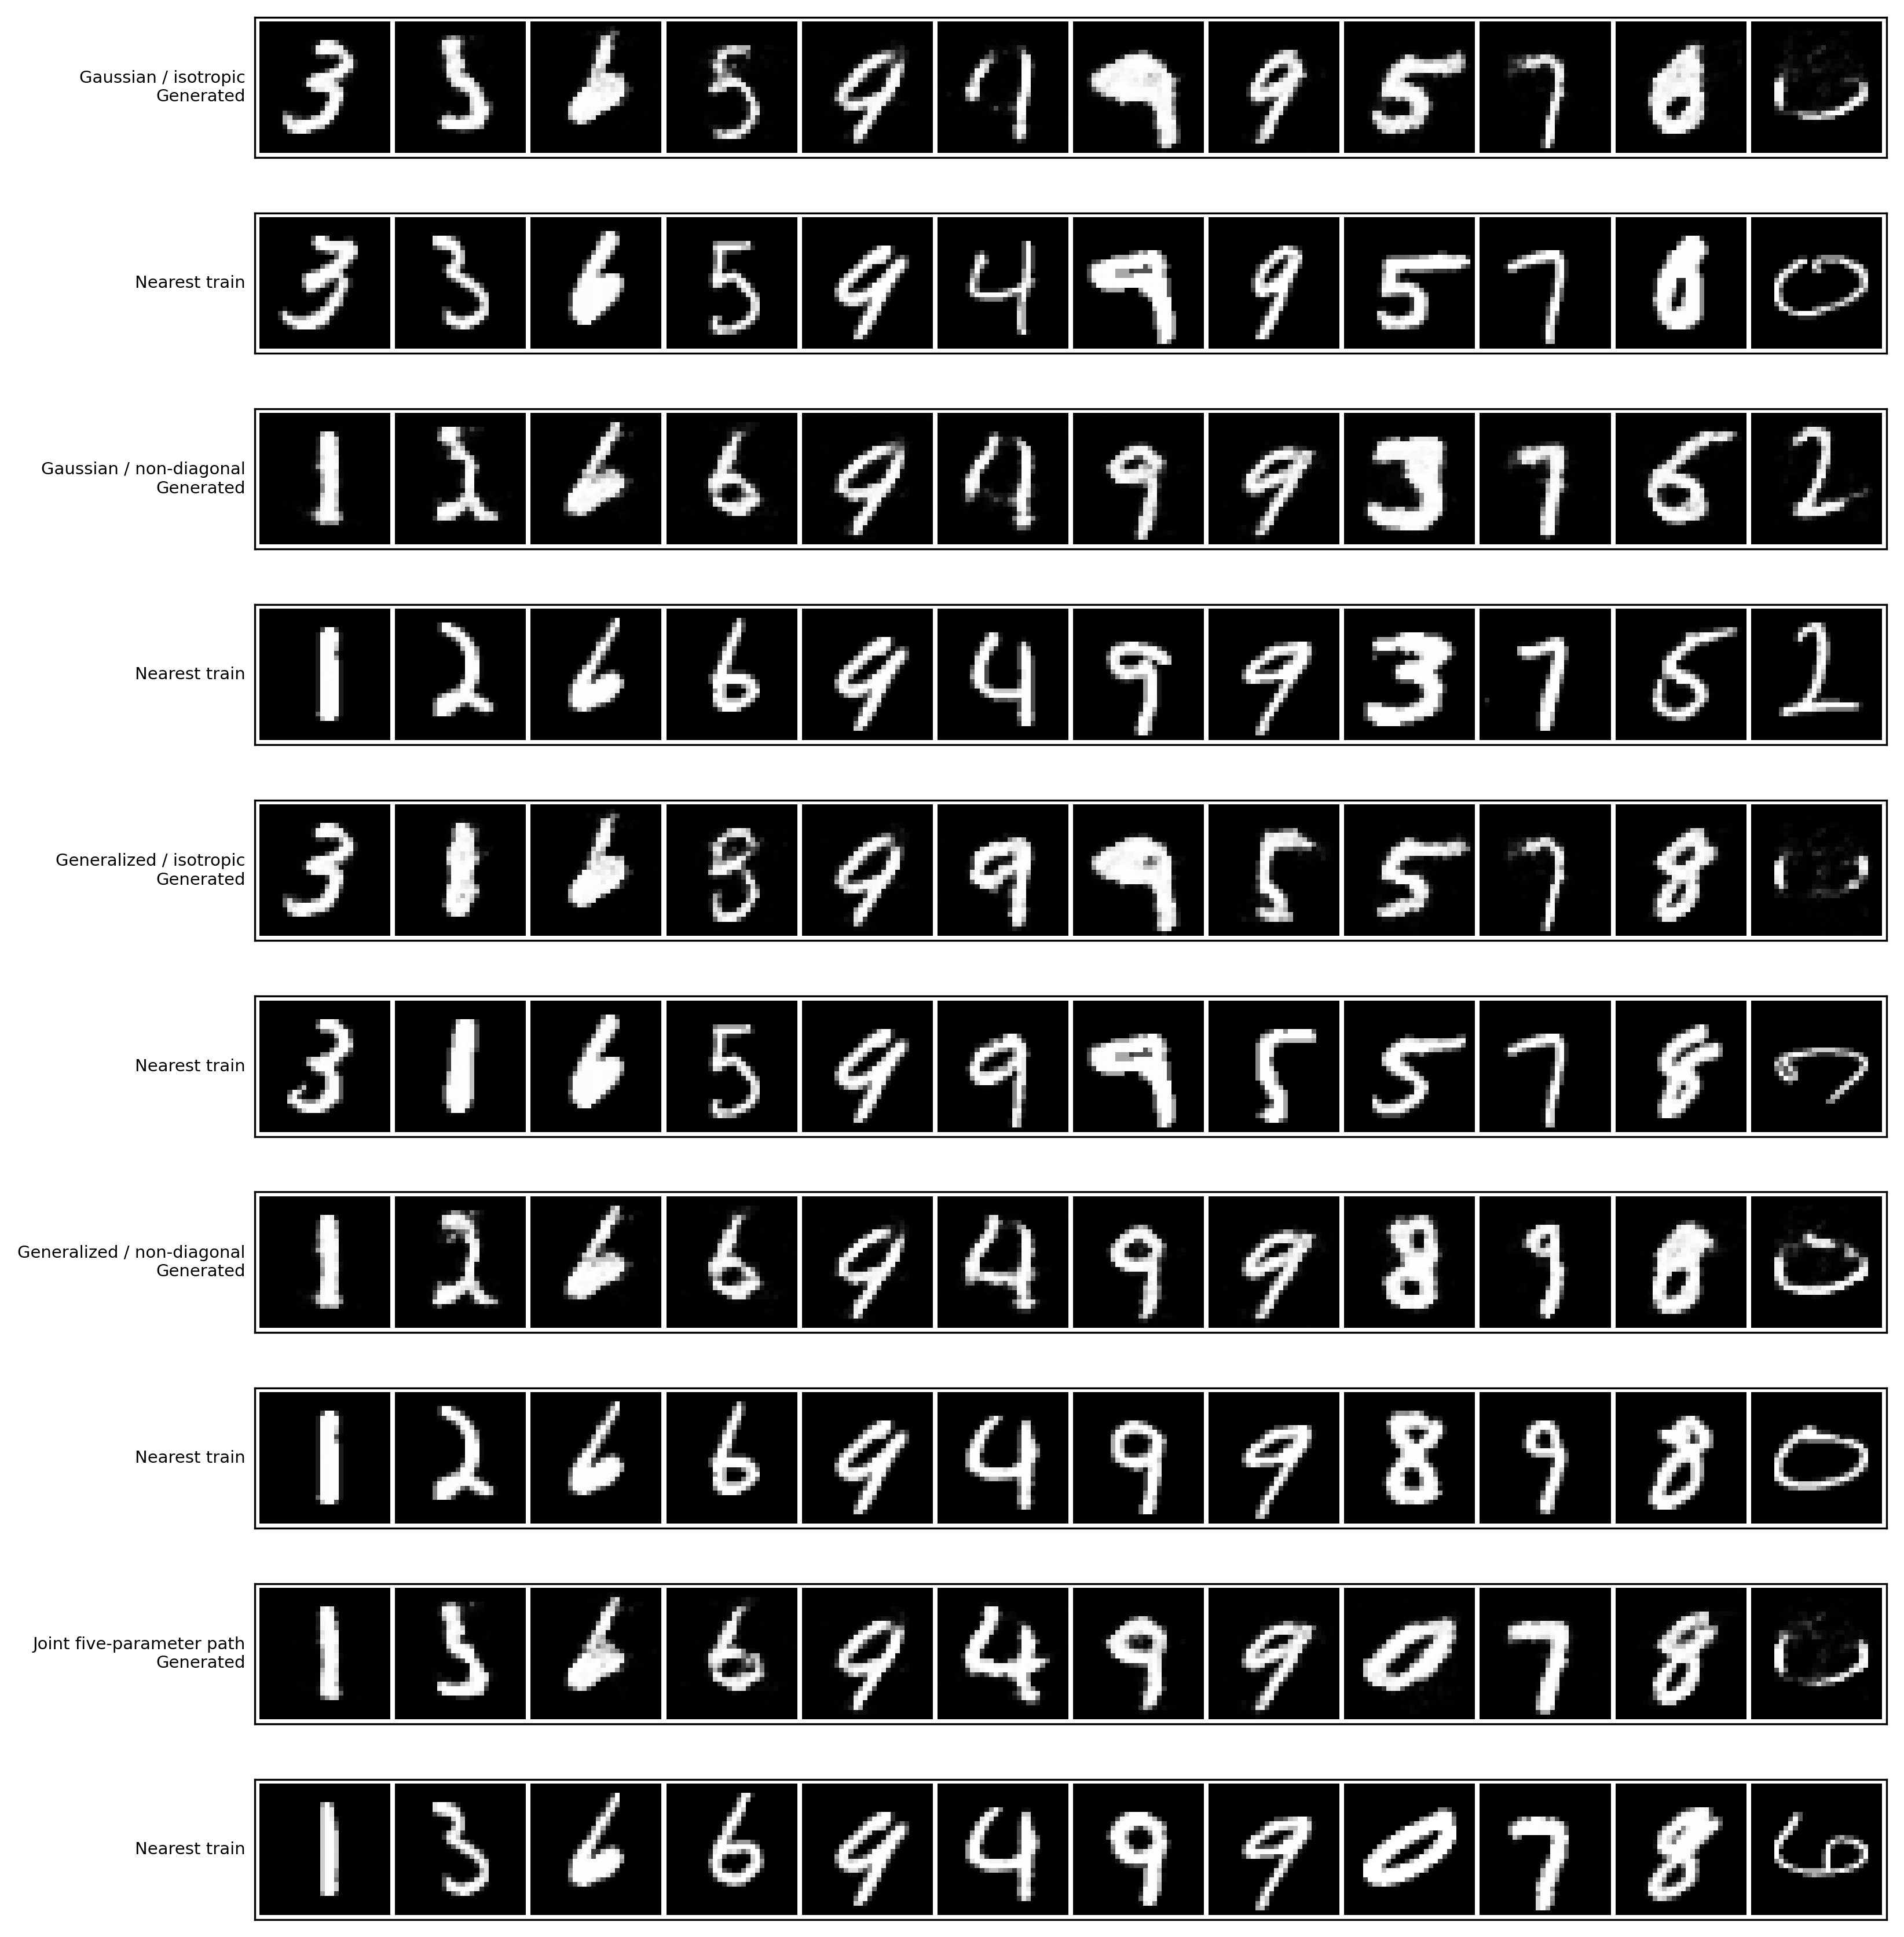

In [19]:
with plt.rc_context(MNIST_PLOT_RC):
    fig, axes = plt.subplots(
        2 * len(mnist_neighbor_paths),
        1,
        figsize=(11.0, 2.3 * len(mnist_neighbor_paths)),
        dpi=300,
    )
    for path_index, path_name in enumerate(mnist_neighbor_paths):
        start = path_index * mnist_neighbors_per_path
        stop = start + mnist_neighbors_per_path
        generated_grid = make_mnist_image_grid(
            mnist_neighbor_queries_by_path[path_name],
            nrow=mnist_neighbors_per_path,
            padding=1,
        )
        neighbor_grid = make_mnist_image_grid(
            mnist_neighbor_matches[start:stop],
            nrow=mnist_neighbors_per_path,
            padding=1,
        )
        generated_axis = axes[2 * path_index]
        neighbor_axis = axes[2 * path_index + 1]
        generated_axis.imshow(
            generated_grid.permute(1, 2, 0).numpy(),
            vmin=0.0,
            vmax=1.0,
        )
        neighbor_axis.imshow(
            neighbor_grid.permute(1, 2, 0).numpy(),
            vmin=0.0,
            vmax=1.0,
        )
        generated_axis.set_ylabel(
            f"{MNIST_PATH_LABELS[path_name]}\nGenerated",
            rotation=0,
            ha="right",
            va="center",
            fontsize=7,
        )
        neighbor_axis.set_ylabel(
            "Nearest train",
            rotation=0,
            ha="right",
            va="center",
            fontsize=7,
        )
    for axis in axes:
        axis.set_xticks([])
        axis.set_yticks([])
    fig.tight_layout(h_pad=0.25)
    fig.savefig(
        MNIST_FIG_DIR / "mnist_nearest_training_images.png",
        bbox_inches="tight",
    )
    fig.savefig(
        MNIST_FIG_DIR / "mnist_nearest_training_images.pdf",
        bbox_inches="tight",
    )


In [20]:
mnist_neighbor_df


,path,sample_index,training_index,pixel_l2_distance,training_label
0,gaussian,0,47539,4.669451,3
1,gaussian,1,24524,4.807211,3
2,gaussian,2,3858,4.678047,6
3,gaussian,3,6300,3.134141,5
4,gaussian,4,20308,3.967598,9
5,gaussian,5,40600,4.699993,4
6,gaussian,6,19778,5.179549,9
7,gaussian,7,11593,3.101594,9
8,gaussian,8,15110,4.685673,5
9,gaussian,9,7494,2.841846,7


# Public classifier and quantitative comparison


The pinned ONNX Model Zoo MNIST-12 classifier supplies class probabilities and penultimate-layer features. The notebook checks its test accuracy and verifies that exposing the feature output preserves its logits.


In [ ]:
MNIST_EVALUATOR_CONFIG = {
    "name": "ONNX Model Zoo MNIST-12",
    "source_repository": "onnx/models",
    "source_commit": "d55d2baeb0d6641643d5295a4f42b545fcf9d9e2",
    "source_url": ONNX_MNIST12_URL,
    "reported_top1_error": 0.011,
    "reference_seed": 20260723,
    "test_batch_size": 512,
    "feature_output_name": ONNX_MNIST12_FEATURE_OUTPUT_NAME,
    "representation": "raw penultimate activation",
    "bootstrap_seed": 20260724,
    "bootstrap_replicates": 1000,
    "bootstrap_confidence": 0.95,
}
MNIST_EVALUATOR_PATH = (
    ROOT / "data" / "mnist" / "evaluators" / "onnx_model_zoo" / "mnist-12.onnx"
)
MNIST_FEATURE_EVALUATOR_PATH = (
    ROOT
    / "data"
    / "mnist"
    / "evaluators"
    / "onnx_model_zoo"
    / "mnist-12-penultimate.onnx"
)
MNIST_QUANTITATIVE_DIR = MNIST_OUT_DIR / "quantitative"
MNIST_QUANTITATIVE_DIR.mkdir(parents=True, exist_ok=True)
mnist_evaluator_downloaded = not MNIST_EVALUATOR_PATH.is_file()
MNIST_EVALUATOR_PATH = ensure_onnx_mnist12_checkpoint(
    MNIST_EVALUATOR_PATH, url=MNIST_EVALUATOR_CONFIG["source_url"]
)
MNIST_FEATURE_EVALUATOR_PATH = ensure_onnx_mnist12_feature_checkpoint(
    MNIST_EVALUATOR_PATH,
    MNIST_FEATURE_EVALUATOR_PATH,
    feature_output_name=MNIST_EVALUATOR_CONFIG["feature_output_name"],
)
mnist_public_classifier = ONNXMNIST12Classifier(MNIST_EVALUATOR_PATH)
mnist_feature_classifier = ONNXMNIST12FeatureClassifier(
    MNIST_EVALUATOR_PATH,
    MNIST_FEATURE_EVALUATOR_PATH,
    feature_output_name=MNIST_EVALUATOR_CONFIG["feature_output_name"],
)
mnist_public_classifier_metadata = mnist_public_classifier.metadata()
mnist_classifier_metadata = mnist_feature_classifier.metadata()
mnist_classifier_metadata["downloaded_this_run"] = mnist_evaluator_downloaded
mnist_classifier_metadata["onnx_version"] = onnx.__version__
mnist_classifier_test_loader, _ = make_mnist_loader(
    ROOT / "data",
    train=False,
    batch_size=MNIST_EVALUATOR_CONFIG["test_batch_size"],
    seed=MNIST_EVALUATOR_CONFIG["reference_seed"],
    num_workers=4,
    download=True,
    shuffle=False,
    drop_last=False,
)


In [ ]:
mnist_classifier_test_correct = 0
mnist_classifier_test_count = 0
mnist_classifier_logit_max_abs_difference = 0.0
mnist_classifier_logit_tolerance = 1e-6

for uint8_images, labels in tqdm(
    mnist_classifier_test_loader,
    desc="Validate public MNIST-12 evaluator",
):
    vectors = uint8_images.reshape(len(uint8_images), -1).float() / 255.0
    _, public_logits = mnist_public_classifier.classify_vectors(vectors)
    _, logits, _ = mnist_feature_classifier.classify_vectors(vectors)
    mnist_classifier_logit_max_abs_difference = max(
        mnist_classifier_logit_max_abs_difference,
        float((public_logits - logits).abs().max()),
    )
    if not torch.allclose(
        public_logits,
        logits,
        atol=mnist_classifier_logit_tolerance,
        rtol=mnist_classifier_logit_tolerance,
    ):
        raise RuntimeError("Exposing the penultimate output changed MNIST-12 logits.")
    labels = labels.cpu()
    mnist_classifier_test_correct += int((logits.argmax(dim=1) == labels).sum())
    mnist_classifier_test_count += len(labels)

mnist_classifier_report = {
    **mnist_classifier_metadata,
    "source_repository": MNIST_EVALUATOR_CONFIG["source_repository"],
    "source_commit": MNIST_EVALUATOR_CONFIG["source_commit"],
    "reported_top1_error": MNIST_EVALUATOR_CONFIG["reported_top1_error"],
    "source_checkpoint_unchanged": True,
    "derived_logit_tolerance": mnist_classifier_logit_tolerance,
    "derived_logit_max_abs_difference": (mnist_classifier_logit_max_abs_difference),
    "test_images": mnist_classifier_test_count,
    "test_accuracy": (mnist_classifier_test_correct / mnist_classifier_test_count),
}
if mnist_classifier_report["test_accuracy"] < 0.98:
    raise RuntimeError(
        "The MNIST evaluator did not reach 98% held-out accuracy; "
        "do not use its generated-sample metrics."
    )
write_json_atomic(
    mnist_classifier_report,
    MNIST_QUANTITATIVE_DIR / "onnx_penultimate_evaluator_report.json",
)


In [ ]:
mnist_classifier_report = json.loads(
    (MNIST_QUANTITATIVE_DIR / "onnx_penultimate_evaluator_report.json").read_text()
)


In [22]:
pd.DataFrame([mnist_classifier_report])


Validate public MNIST-12 evaluator: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 20/20 [00:08<00:00,  2.23it/s]


,name,source_model_path,source_sha256,feature_model_path,feature_model_sha256,input_name,logit_output_name,feature_output_name,feature_shape,feature_dimension,...,source_repository,source_commit,reported_top1_error,source_checkpoint_unchanged,derived_logit_tolerance,derived_logit_max_abs_difference,test_images,test_cross_entropy,test_accuracy,test_mean_confidence
0,ONNX Model Zoo MNIST-12 with exposed penultima...,SUPPLEMENT_ROOT/data/mnist/evaluators/...,5c688690f8bacf667d4c2074af5ad0646ca328d7ab03ec...,SUPPLEMENT_ROOT/data/mnist/evaluators/...,7776f7381dc31fb3dbdcad97ff4361e4650b45bde7877e...,Input3,Plus214_Output_0,Pooling160_Output_0_reshape0,"[1, 256]",256,...,onnx/models,d55d2baeb0d6641643d5295a4f42b545fcf9d9e2,0.011,True,0.000001,0.0,10000,0.035029,0.989,0.992537


## Reference bank and real-data pools

One shuffled split of the 10,000 MNIST test images supplies three disjoint groups: the fixed 2,048-image feature reference bank that every ED is computed against, the matched real-baseline subsets consumed by the quantitative table, and the remaining pool used for the null distribution below.

In [23]:
mnist_test_dataset = MNISTUint8Dataset(
    ROOT / "data",
    train=False,
    download=True,
)
mnist_test_vectors = mnist_test_dataset.data.reshape(-1, MNIST_DIM).float() / 255.0
mnist_test_class_probabilities = torch.bincount(
    mnist_test_dataset.targets,
    minlength=10,
).double()
mnist_test_class_probabilities /= mnist_test_class_probabilities.sum()

mnist_reference_generator = torch.Generator(device="cpu").manual_seed(
    MNIST_EVALUATOR_CONFIG["reference_seed"] + 1
)
mnist_test_permutation = torch.randperm(
    len(mnist_test_vectors),
    generator=mnist_reference_generator,
)
mnist_feature_reference_indices = mnist_test_permutation[:2048]
mnist_real_baseline_pool = mnist_test_permutation[2048:]
mnist_feature_reference_vectors = mnist_test_vectors[mnist_feature_reference_indices]
_, _, mnist_feature_reference = mnist_feature_classifier.classify_vectors(
    mnist_feature_reference_vectors,
)
print(
    f"Reference bank: {len(mnist_feature_reference)} images; "
    f"baseline/null pool: {len(mnist_real_baseline_pool)} images."
)


Reference bank: 2048 images; baseline/null pool: 7952 images.


# Quantitative generation results

The primary table pools all 768 endpoint images for each path. The reference bank contains 2,048 held-out images, and disjoint test images supply the real baseline. Seed-stratified bootstrap intervals accompany the generated feature energy distances and the confidence and class-TV estimates. The real-versus-real feature energy distance is compared with its empirical null distribution.


## Feature-ED null distribution

Repeated draws of held-out real images estimate the sampling variation of the signed unbiased feature energy distance against the fixed reference bank. Each draw is disjoint from that bank and the real-baseline images. The 95th percentile provides a reference for the generated-sample results at the same sample size.


In [ ]:
MNIST_ED_NULL_DRAWS = 256
mnist_ed_null_generator = torch.Generator(device="cpu").manual_seed(
    MNIST_EVALUATOR_CONFIG["bootstrap_seed"] + 1000
)
mnist_pooled_batch_size = mnist_samples_per_seed * len(MNIST_GENERATION_SEEDS)
mnist_null_pool_indices = mnist_real_baseline_pool[mnist_pooled_batch_size:]
_, _, mnist_null_pool_features = mnist_feature_classifier.classify_vectors(
    mnist_test_vectors[mnist_null_pool_indices]
)
mnist_ed_null_rows = []
for batch_size in (mnist_samples_per_seed, mnist_pooled_batch_size):
    for draw_index in range(MNIST_ED_NULL_DRAWS):
        subset = torch.randperm(
            len(mnist_null_pool_features),
            generator=mnist_ed_null_generator,
        )[:batch_size]
        mnist_ed_null_rows.append(
            {
                "batch_size": int(batch_size),
                "draw_index": draw_index,
                "feature_energy_distance": mnist_representation_energy_distance(
                    mnist_null_pool_features[subset],
                    mnist_feature_reference,
                    device=MNIST_DEVICE,
                    normalize=False,
                ),
            }
        )
mnist_ed_null_df = pd.DataFrame(mnist_ed_null_rows)
write_csv_atomic(
    mnist_ed_null_df,
    MNIST_QUANTITATIVE_DIR / "feature_ed_null_distribution.csv",
)


In [ ]:
mnist_ed_null_df = pd.read_csv(
    MNIST_QUANTITATIVE_DIR / "feature_ed_null_distribution.csv"
)
mnist_ed_null_summary = (
    mnist_ed_null_df.groupby("batch_size")["feature_energy_distance"]
    .agg(
        mean="mean",
        median="median",
        quantile_05=lambda values: values.quantile(0.05),
        quantile_95=lambda values: values.quantile(0.95),
        minimum="min",
        maximum="max",
    )
    .round(5)
)
mnist_ed_null_q95 = {
    int(batch_size): float(row["quantile_95"])
    for batch_size, row in mnist_ed_null_summary.iterrows()
}


In [24]:
mnist_ed_null_summary


,mean,median,quantile_05,quantile_95,minimum,maximum
batch_size,,,,,,
256,-0.00047,-0.00163,-0.02801,0.03296,-0.03659,0.08605
768,0.00208,0.00088,-0.00979,0.01736,-0.01380,0.04848


In [ ]:
mnist_quantitative_rows = []
mnist_class_count_rows = []
mnist_quantitative_batches = {}

for (path_name, generation_seed), batch in tqdm(
    sorted(mnist_final_batches.items()),
    desc="Quantitative MNIST generation metrics",
):
    vectors = batch.clamp(0.0, 1.0)
    probabilities, _, features = mnist_feature_classifier.classify_vectors(
        vectors,
    )
    prediction_metrics, class_counts = mnist_prediction_metrics(
        probabilities,
        target_class_probabilities=mnist_test_class_probabilities,
    )
    nearest_train_rmse = nearest_reference_pixel_rmse(
        vectors,
        mnist_training_vectors,
        device=MNIST_DEVICE,
    )
    mnist_quantitative_batches[
        (MNIST_PRODUCTION_RUN_NAME, path_name, int(generation_seed))
    ] = {
        "source_type": "generated",
        "probabilities": probabilities,
        "features": features,
    }
    mnist_quantitative_rows.append(
        {
            "source_type": "generated",
            "run_name": MNIST_PRODUCTION_RUN_NAME,
            "model_label": MNIST_PRODUCTION_LABEL,
            "path": path_name,
            "generation_seed": int(generation_seed),
            "n_samples": len(vectors),
            **{
                metric: prediction_metrics[metric]
                for metric in (
                    "mean_classifier_confidence",
                    "classes_present",
                    "class_distribution_tv",
                )
            },
            "penultimate_feature_energy_distance": mnist_representation_energy_distance(
                features,
                mnist_feature_reference,
                device=MNIST_DEVICE,
                normalize=False,
            ),
            "nearest_train_pixel_rmse": float(nearest_train_rmse.mean()),
        }
    )
    for digit, count in enumerate(class_counts.tolist()):
        mnist_class_count_rows.append(
            {
                "source_type": "generated",
                "run_name": MNIST_PRODUCTION_RUN_NAME,
                "model_label": MNIST_PRODUCTION_LABEL,
                "path": path_name,
                "generation_seed": int(generation_seed),
                "predicted_digit": digit,
                "count": count,
                "fraction": count / len(vectors),
            }
        )

mnist_real_baseline_offset = 0
mnist_real_baseline_indices_by_seed = {}
for generation_seed in MNIST_GENERATION_SEEDS:
    baseline_size = mnist_samples_per_seed
    baseline_indices = mnist_real_baseline_pool[
        mnist_real_baseline_offset : mnist_real_baseline_offset + baseline_size
    ]
    if len(baseline_indices) != baseline_size:
        raise RuntimeError("not enough disjoint MNIST test images for baseline")
    mnist_real_baseline_offset += baseline_size
    mnist_real_baseline_indices_by_seed[int(generation_seed)] = baseline_indices.clone()
    vectors = mnist_test_vectors[baseline_indices]
    probabilities, _, features = mnist_feature_classifier.classify_vectors(
        vectors,
    )
    prediction_metrics, class_counts = mnist_prediction_metrics(
        probabilities,
        target_class_probabilities=mnist_test_class_probabilities,
    )
    nearest_train_rmse = nearest_reference_pixel_rmse(
        vectors,
        mnist_training_vectors,
        device=MNIST_DEVICE,
    )
    mnist_quantitative_batches[
        ("real_mnist_test", "real_test", int(generation_seed))
    ] = {
        "source_type": "real",
        "probabilities": probabilities,
        "features": features,
    }
    mnist_quantitative_rows.append(
        {
            "source_type": "real",
            "run_name": "real_mnist_test",
            "model_label": "Real MNIST test subsample",
            "path": "real_test",
            "generation_seed": int(generation_seed),
            "n_samples": len(vectors),
            **{
                metric: prediction_metrics[metric]
                for metric in (
                    "mean_classifier_confidence",
                    "classes_present",
                    "class_distribution_tv",
                )
            },
            "penultimate_feature_energy_distance": mnist_representation_energy_distance(
                features,
                mnist_feature_reference,
                device=MNIST_DEVICE,
                normalize=False,
            ),
            "nearest_train_pixel_rmse": float(nearest_train_rmse.mean()),
        }
    )
    for digit, count in enumerate(class_counts.tolist()):
        mnist_class_count_rows.append(
            {
                "source_type": "real",
                "run_name": "real_mnist_test",
                "model_label": "Real MNIST test subsample",
                "path": "real_test",
                "generation_seed": int(generation_seed),
                "predicted_digit": digit,
                "count": count,
                "fraction": count / len(vectors),
            }
        )

mnist_quantitative_raw_df = pd.DataFrame(mnist_quantitative_rows)
mnist_class_counts_raw_df = pd.DataFrame(mnist_class_count_rows)
write_csv_atomic(
    mnist_quantitative_raw_df,
    MNIST_QUANTITATIVE_DIR / "generation_metrics_raw.csv",
)
write_csv_atomic(
    mnist_class_counts_raw_df,
    MNIST_QUANTITATIVE_DIR / "predicted_class_counts_raw.csv",
)
save_torch_atomic(
    {
        "evaluator_path": str(MNIST_EVALUATOR_PATH),
        "feature_evaluator_path": str(MNIST_FEATURE_EVALUATOR_PATH),
        "evaluator_config": MNIST_EVALUATOR_CONFIG,
        "public_evaluator_metadata": mnist_public_classifier_metadata,
        "evaluator_metadata": mnist_classifier_metadata,
        "feature_reference_indices": mnist_feature_reference_indices,
        "real_baseline_indices_by_seed": mnist_real_baseline_indices_by_seed,
    },
    MNIST_QUANTITATIVE_DIR / "evaluation_reference.pt",
)
save_torch_atomic(
    mnist_quantitative_batches,
    MNIST_QUANTITATIVE_DIR / "quantitative_batches.pt",
)


In [ ]:
mnist_quantitative_raw_df = pd.read_csv(
    MNIST_QUANTITATIVE_DIR / "generation_metrics_raw.csv"
)
mnist_class_counts_raw_df = pd.read_csv(
    MNIST_QUANTITATIVE_DIR / "predicted_class_counts_raw.csv"
)
mnist_quantitative_batches = torch.load(
    MNIST_QUANTITATIVE_DIR / "quantitative_batches.pt",
    map_location="cpu",
    weights_only=False,
)


In [25]:
mnist_quantitative_raw_df


Quantitative MNIST generation metrics: 100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 15/15 [00:03<00:00,  4.95it/s]


,analysis_version,source_type,run_name,model_label,path,generation_seed,n_samples,mean_classifier_confidence,high_confidence_fraction,normalized_class_entropy,classes_present,class_distribution_tv,penultimate_feature_energy_distance,logit_energy_distance,nearest_train_pixel_rmse,median_nearest_train_pixel_rmse
0,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,fixed_non_diagonal,2718,256,0.963211,0.933594,0.982476,10,0.129325,0.203320,0.008459,0.146021,0.147904
1,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,fixed_non_diagonal,3141,256,0.964927,0.929688,0.989427,10,0.079850,0.164196,0.003799,0.142134,0.145415
2,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,fixed_non_diagonal,5772,256,0.970532,0.937500,0.976019,10,0.127487,0.317749,0.012837,0.139865,0.143071
3,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,gaussian,2718,256,0.908786,0.839844,0.970392,10,0.136125,0.554377,0.016150,0.143816,0.146269
4,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,gaussian,3141,256,0.924059,0.851562,0.968910,10,0.144281,0.528872,0.018058,0.141011,0.146503
5,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,gaussian,5772,256,0.933197,0.890625,0.940350,10,0.226975,0.658337,0.029041,0.139870,0.141858
6,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,gaussian_non_diagonal,2718,256,0.952046,0.910156,0.990562,10,0.084456,0.198677,0.001382,0.145577,0.147889
7,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,gaussian_non_diagonal,3141,256,0.964668,0.925781,0.978535,10,0.126606,0.230511,0.004305,0.139749,0.144242
8,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,gaussian_non_diagonal,5772,256,0.974985,0.957031,0.966917,10,0.150706,0.303894,0.012414,0.137061,0.140063
9,mnist_penultimate_ed_bootstrap_v2,generated,posterior,h2560 / rho4 full,generalized_isotropic,2718,256,0.903048,0.828125,0.972151,10,0.153725,0.702545,0.013162,0.141438,0.144201


## Pooled path comparison


Class coverage and mean nearest-training-image RMSE use all endpoints from each path. The primary table reports pooled feature energy distance, confidence, and class TV. Its bootstrap resamples within each of the three generation seeds. The real feature-ED row uses the null distribution above because the energy distance is a degenerate U-statistic at the null.


In [ ]:
mnist_supporting_rows = []
for (source_type, path_name), group in mnist_quantitative_raw_df.groupby(
    ["source_type", "path"], sort=False
):
    counts = (
        mnist_class_counts_raw_df.loc[
            (mnist_class_counts_raw_df["source_type"] == source_type)
            & (mnist_class_counts_raw_df["path"] == path_name)
        ]
        .groupby("predicted_digit")["count"]
        .sum()
    )
    mnist_supporting_rows.append(
        {
            "Path": (
                "Real MNIST test images"
                if source_type == "real"
                else MNIST_PATH_LABELS[path_name]
            ),
            "Images": int(group["n_samples"].sum()),
            "Classes present": int((counts > 0).sum()),
            "Mean nearest-training-image RMSE": float(
                np.average(
                    group["nearest_train_pixel_rmse"], weights=group["n_samples"]
                )
            ),
        }
    )
mnist_supporting_path_order = {
    "Real MNIST test images": 0,
    **{label: index for index, label in enumerate(MNIST_PATH_LABELS.values(), start=1)},
}
mnist_supporting_summary_df = pd.DataFrame(mnist_supporting_rows)
mnist_supporting_summary_df["path_order"] = mnist_supporting_summary_df["Path"].map(
    mnist_supporting_path_order
)
mnist_supporting_summary_df = (
    mnist_supporting_summary_df.sort_values("path_order")
    .drop(columns="path_order")
    .reset_index(drop=True)
)
write_csv_atomic(
    mnist_supporting_summary_df,
    MNIST_QUANTITATIVE_DIR / "supporting_generation_summary.csv",
)


In [ ]:
mnist_supporting_summary_df = pd.read_csv(
    MNIST_QUANTITATIVE_DIR / "supporting_generation_summary.csv"
)


In [35]:
mnist_supporting_summary_df


,source_type,model_label,path,n_batches,n_images_total,mean_classifier_confidence_mean,mean_classifier_confidence_std,high_confidence_fraction_mean,high_confidence_fraction_std,normalized_class_entropy_mean,...,classes_present_mean,classes_present_std,class_distribution_tv_mean,class_distribution_tv_std,penultimate_feature_energy_distance_mean,penultimate_feature_energy_distance_std,logit_energy_distance_mean,logit_energy_distance_std,nearest_train_pixel_rmse_mean,nearest_train_pixel_rmse_std
0,real,Real MNIST test subsample,real_test,3,768,0.992647,0.002598,0.988281,0.006766,0.985028,...,10.0,0.0,0.104752,0.020496,0.015530,0.019121,0.002943,0.003597,0.146631,0.002537
1,generated,h2560 / rho4 full,gaussian,3,768,0.922014,0.012333,0.860677,0.026589,0.959884,...,10.0,0.0,0.169127,0.050263,0.580528,0.068580,0.021083,0.006957,0.141566,0.002030
2,generated,h2560 / rho4 full,gaussian_non_diagonal,3,768,0.963900,0.011489,0.930990,0.023868,0.978671,...,10.0,0.0,0.120590,0.033532,0.244361,0.053958,0.006034,0.005716,0.140796,0.004353
3,generated,h2560 / rho4 full,generalized_isotropic,3,768,0.907802,0.007458,0.835938,0.013532,0.973421,...,10.0,0.0,0.145152,0.017455,0.647587,0.065604,0.015360,0.003403,0.138726,0.002405
4,generated,h2560 / rho4 full,fixed_non_diagonal,3,768,0.966223,0.003829,0.933594,0.003906,0.982641,...,10.0,0.0,0.112221,0.028049,0.228422,0.079795,0.008365,0.004520,0.142673,0.003114
5,generated,h2560 / rho4 full,joint,3,768,0.959836,0.003743,0.920573,0.009021,0.978071,...,10.0,0.0,0.128981,0.010471,0.303418,0.033338,0.011135,0.001702,0.138926,0.002306


In [36]:
MNIST_PRIMARY_METRICS = [
    "penultimate_feature_energy_distance",
    "mean_classifier_confidence",
    "class_distribution_tv",
]
mnist_primary_group_specs = [
    {
        "source_type": "real",
        "run_name": "real_mnist_test",
        "model_label": "Real MNIST test subsample",
        "path": "real_test",
        "display_label": "Real MNIST vs. real reference",
    },
] + [
    {
        "source_type": "generated",
        "run_name": MNIST_PRODUCTION_RUN_NAME,
        "model_label": MNIST_PRODUCTION_LABEL,
        "path": path_name,
        "display_label": display_label,
    }
    for path_name, display_label in MNIST_PATH_LABELS.items()
]
mnist_bootstrap_alpha = (1.0 - MNIST_EVALUATOR_CONFIG["bootstrap_confidence"]) / 2.0
mnist_pooled_summary_rows = []
mnist_bootstrap_rows = []

for group_index, group_spec in enumerate(mnist_primary_group_specs):
    probability_batches = []
    feature_batches = []
    for generation_seed in MNIST_GENERATION_SEEDS:
        batch_key = (
            group_spec["run_name"],
            group_spec["path"],
            int(generation_seed),
        )
        if batch_key not in mnist_quantitative_batches:
            raise RuntimeError(f"missing quantitative batch {batch_key}")
        batch = mnist_quantitative_batches[batch_key]
        probability_batches.append(batch["probabilities"])
        feature_batches.append(batch["features"])

    bootstrap_result = mnist_stratified_bootstrap_primary_metrics(
        probability_batches,
        feature_batches,
        mnist_feature_reference,
        mnist_test_class_probabilities,
        n_bootstrap=MNIST_EVALUATOR_CONFIG["bootstrap_replicates"],
        seed=MNIST_EVALUATOR_CONFIG["bootstrap_seed"] + group_index,
        device=MNIST_DEVICE,
    )
    pooled_row = {
        **group_spec,
        "n_seeds": bootstrap_result["n_seeds"],
        "samples_per_seed": bootstrap_result["samples_per_seed"],
        "n_samples": bootstrap_result["n_samples"],
    }
    for metric in MNIST_PRIMARY_METRICS:
        bootstrap_values = bootstrap_result["bootstrap"][metric]
        pooled_row[metric] = bootstrap_result["point"][metric]
        if (
            group_spec["source_type"] == "real"
            and metric == "penultimate_feature_energy_distance"
        ):
            pooled_row[f"{metric}_ci_low"] = np.nan
            pooled_row[f"{metric}_ci_high"] = np.nan
            continue
        pooled_row[f"{metric}_ci_low"] = float(
            np.quantile(bootstrap_values, mnist_bootstrap_alpha)
        )
        pooled_row[f"{metric}_ci_high"] = float(
            np.quantile(bootstrap_values, 1.0 - mnist_bootstrap_alpha)
        )
    mnist_pooled_summary_rows.append(pooled_row)

    for bootstrap_index in range(MNIST_EVALUATOR_CONFIG["bootstrap_replicates"]):
        bootstrap_row = {
            "source_type": group_spec["source_type"],
            "run_name": group_spec["run_name"],
            "path": group_spec["path"],
            "bootstrap_index": bootstrap_index,
        }
        for metric in MNIST_PRIMARY_METRICS:
            if (
                group_spec["source_type"] == "real"
                and metric == "penultimate_feature_energy_distance"
            ):
                continue
            bootstrap_row[metric] = float(
                bootstrap_result["bootstrap"][metric][bootstrap_index]
            )
        mnist_bootstrap_rows.append(bootstrap_row)

mnist_pooled_summary_df = pd.DataFrame(mnist_pooled_summary_rows)
mnist_bootstrap_raw_df = pd.DataFrame(mnist_bootstrap_rows)

mnist_n_seeds = int(mnist_pooled_summary_df["n_seeds"].iloc[0])
mnist_pooled_samples_per_path = int(mnist_pooled_summary_df["n_samples"].iloc[0])
write_csv_atomic(
    mnist_pooled_summary_df,
    MNIST_QUANTITATIVE_DIR / "pooled_bootstrap_summary.csv",
)
write_csv_atomic(
    mnist_bootstrap_raw_df,
    MNIST_QUANTITATIVE_DIR / "bootstrap_metrics_raw.csv",
)
write_json_atomic(
    {
        "paths": list(MNIST_PATH_LABELS),
        "path_labels": dict(MNIST_PATH_LABELS),
        "configured_path_files": {
            path_name: str(config_path.relative_to(ROOT))
            for path_name, config_path in MNIST_CONFIGURED_PATH_FILES.items()
        },
        "n_seeds": mnist_n_seeds,
        "samples_per_seed": mnist_samples_per_seed,
        "pooled_samples_per_path": mnist_pooled_samples_per_path,
        "reference_images": len(mnist_feature_reference),
        "bootstrap_replicates": MNIST_EVALUATOR_CONFIG["bootstrap_replicates"],
        "bootstrap_confidence": MNIST_EVALUATOR_CONFIG["bootstrap_confidence"],
        "feature_ed_null_q95": mnist_ed_null_q95,
    },
    MNIST_QUANTITATIVE_DIR / "protocol.json",
)


In [ ]:
mnist_pooled_summary_df = pd.read_csv(
    MNIST_QUANTITATIVE_DIR / "pooled_bootstrap_summary.csv"
)
mnist_paper_table_df = pd.DataFrame(
    {
        "Path": mnist_pooled_summary_df["display_label"],
        "External penultimate-feature ED (lower is better)": [
            (
                f"{row.penultimate_feature_energy_distance:.3f}"
                if row.source_type == "real"
                else (
                    f"{row.penultimate_feature_energy_distance:.3f} "
                    f"[{row.penultimate_feature_energy_distance_ci_low:.3f}, "
                    f"{row.penultimate_feature_energy_distance_ci_high:.3f}]"
                )
            )
            for row in mnist_pooled_summary_df.itertuples()
        ],
        "Mean classifier confidence (higher is better)": [
            (
                f"{row.mean_classifier_confidence:.3f} "
                f"[{row.mean_classifier_confidence_ci_low:.3f}, "
                f"{row.mean_classifier_confidence_ci_high:.3f}]"
            )
            for row in mnist_pooled_summary_df.itertuples()
        ],
        "Class-distribution TV (lower is better)": [
            (
                f"{row.class_distribution_tv:.3f} "
                f"[{row.class_distribution_tv_ci_low:.3f}, "
                f"{row.class_distribution_tv_ci_high:.3f}]"
            )
            for row in mnist_pooled_summary_df.itertuples()
        ],
    }
)
write_csv_atomic(
    mnist_paper_table_df,
    MNIST_QUANTITATIVE_DIR / "paper_quantitative_table.csv",
)


In [37]:
mnist_paper_table_df = pd.read_csv(
    MNIST_QUANTITATIVE_DIR / "paper_quantitative_table.csv"
)
mnist_paper_table_df


,Path,External penultimate-feature ED (lower is better),Mean classifier confidence (higher is better),Class-distribution TV (lower is better)
0,Real MNIST vs. real reference,"0.0153 [0.0279, 0.0806]","0.993 [0.989, 0.996]","0.074 [0.058, 0.117]"
1,Gaussian / isotropic,"0.5744 [0.5056, 0.7112]","0.922 [0.910, 0.934]","0.162 [0.133, 0.198]"
2,Gaussian / non-diagonal,"0.2469 [0.2148, 0.3601]","0.964 [0.956, 0.971]","0.111 [0.089, 0.150]"
3,Generalized / isotropic,"0.6368 [0.5482, 0.8077]","0.908 [0.893, 0.921]","0.113 [0.089, 0.152]"
4,Generalized / non-diagonal,"0.2184 [0.1863, 0.3238]","0.966 [0.959, 0.973]","0.085 [0.066, 0.124]"
5,Joint five-parameter path,"0.3025 [0.2585, 0.4238]","0.960 [0.951, 0.968]","0.107 [0.081, 0.142]"
